In [38]:
import random
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from torch.utils.data import TensorDataset, DataLoader

import time, copy
from tqdm import tqdm

In [10]:
ROLL_NUMBER = "M26MAC007"          
SEED = int("".join(c for c in ROLL_NUMBER if c.isdigit()))
print("Seed:", SEED)

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed % 2**32)
    torch.manual_seed(seed)
    if torch.backends.mps.is_available():
        torch.mps.manual_seed(seed)

set_seed()
if torch.backends.mps.is_available():
    device = "mps"          
elif torch.cuda.is_available():
    device = "cuda"
else:
    device = "cpu"
print("Device:", device)

torch.set_num_threads(12)   

Seed: 26007
Device: mps


In [12]:

train_full = torchvision.datasets.CIFAR10(root="./data", train=True, download=True)
test_set   = torchvision.datasets.CIFAR10(root="./data", train=False, download=True)


X_all  = torch.tensor(train_full.data).permute(0, 3, 1, 2).float() / 255.0
y_all  = torch.tensor(train_full.targets)
X_test = torch.tensor(test_set.data).permute(0, 3, 1, 2).float() / 255.0
y_test = torch.tensor(test_set.targets)
classes = train_full.classes


100%|█████████████████████████████████████████| 170M/170M [23:11<00:00, 123kB/s]


In [13]:
idx = np.arange(len(y_all))
train_idx, val_idx = train_test_split(
    idx, test_size=5000, stratify=y_all.numpy(), random_state=SEED % 2**32
)
X_train, y_train = X_all[train_idx], y_all[train_idx]
X_val,   y_val   = X_all[val_idx],   y_all[val_idx]

print("Train:", X_train.shape, " Val:", X_val.shape, " Test:", X_test.shape)
print("Val images per class:", torch.bincount(y_val).tolist())  

Train: torch.Size([45000, 3, 32, 32])  Val: torch.Size([5000, 3, 32, 32])  Test: torch.Size([10000, 3, 32, 32])
Val images per class: [500, 500, 500, 500, 500, 500, 500, 500, 500, 500]


In [14]:
mean = X_train.mean(dim=(0, 2, 3), keepdim=True)
std  = X_train.std(dim=(0, 2, 3), keepdim=True)
norm = lambda x: (x - mean) / std

In [15]:
def make_loader(X, y, shuffle, bs=128):
    g = torch.Generator().manual_seed(SEED)
    return DataLoader(TensorDataset(norm(X), y), batch_size=bs,
                      shuffle=shuffle, generator=g)

train_loader = make_loader(X_train, y_train, shuffle=True)
val_loader   = make_loader(X_val,   y_val,   shuffle=False)
test_loader  = make_loader(X_test,  y_test,  shuffle=False)   

def count_params(model):
    return sum(p.numel() for p in model.parameters())

In [41]:
class MLP(nn.Module):
    def __init__(self, hidden=512, dropout=0.0):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),                 
            nn.Linear(3072, hidden), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(hidden, hidden), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(hidden, 10),        
        )

    def forward(self, x):
        return self.net(x)

mlp_base  = MLP(hidden=512).to(device)
mlp_wide  = MLP(hidden=1024).to(device)
mlp_shift = MLP(hidden=512).to(device)

for name, m in [("MLP-base", mlp_base), ("MLP-wide", mlp_wide), ("MLP-shift", mlp_shift)]:
    print(name, count_params(m))

MLP-base 1841162
MLP-wide 4206602
MLP-shift 1841162


In [31]:
from torchvision.transforms import v2
from torch.utils.data import Dataset

class AugDataset(Dataset):
    def __init__(self, X, y, transform=None):
        self.X, self.y, self.transform = X, y, transform
    def __len__(self):
        return len(self.y)
    def __getitem__(self, i):
        x = self.X[i]
        if self.transform:
            x = self.transform(x)
        return x, self.y[i]

shift_aug = v2.RandomCrop(32, padding=4, fill=0)     # random shift up to +/- 4 px

g = torch.Generator().manual_seed(SEED)
shift_loader = DataLoader(AugDataset(norm(X_train), y_train, shift_aug),
                          batch_size=128, shuffle=True, generator=g)

In [32]:
@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    total_loss, correct, n = 0.0, 0, 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        out = model(x)
        total_loss += F.cross_entropy(out, y, reduction="sum").item()
        correct += (out.argmax(1) == y).sum().item()
        n += y.size(0)
    return total_loss / n, correct / n

In [63]:
def fit(model, lr, epochs=40, loader=None, val_dl=None, weight_decay=0.0,
        verbose=True, desc="training"):
    if loader is None:
        loader = train_loader
    if val_dl is None:
        val_dl = val_loader
    model = model.to(device)
    opt = torch.optim.SGD(model.parameters(), lr=lr, momentum=0.9,
                          weight_decay=weight_decay)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)

    hist = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
    best_acc, best_state = 0.0, None

    pbar = tqdm(range(1, epochs + 1), desc=desc, leave=verbose)
    for ep in pbar:
        # ---- train one epoch ----
        model.train()
        tot_loss, correct, n = 0.0, 0, 0
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            out = model(x)
            loss = F.cross_entropy(out, y)
            opt.zero_grad()
            loss.backward()
            opt.step()
            tot_loss += loss.item() * y.size(0)
            correct += (out.argmax(1) == y).sum().item()
            n += y.size(0)
        sched.step()

        # ---- check on validation ----
        val_loss, val_acc = evaluate(model, val_dl)
        hist["train_loss"].append(tot_loss / n)
        hist["train_acc"].append(correct / n)
        hist["val_loss"].append(val_loss)
        hist["val_acc"].append(val_acc)

        # ---- keep best epoch (chosen on VALIDATION) ----
        if val_acc > best_acc:
            best_acc, best_state = val_acc, copy.deepcopy(model.state_dict())

        pbar.set_postfix(train=f"{correct/n:.3f}", val=f"{val_acc:.3f}",
                         best=f"{best_acc:.3f}")

    model.load_state_dict(best_state)
    hist["best_val_acc"] = best_acc
    return model, hist

In [43]:
def plot_curves(histories, title=""):
    fig, ax = plt.subplots(1, 2, figsize=(12, 4), dpi=800)
    for name, h in histories.items():
        ax[0].plot(h["train_acc"], "--", label=f"{name} train")
        ax[0].plot(h["val_acc"],   "-",  label=f"{name} val")
        ax[1].plot(h["train_loss"], "--", label=f"{name} train")
        ax[1].plot(h["val_loss"],   "-",  label=f"{name} val")
    ax[0].set(title="Accuracy", xlabel="epoch")
    ax[1].set(title="Loss", xlabel="epoch")
    for a in ax:
        a.legend(fontsize=8)
        a.grid(alpha=0.3)
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

In [39]:
LRS = [0.1, 0.03, 0.01]
EPOCHS = 40

configs = {
    "MLP-base":  dict(hidden=512,  loader=train_loader),
    "MLP-wide":  dict(hidden=1024, loader=train_loader),
    "MLP-shift": dict(hidden=512,  loader=shift_loader),
}

best_lr = {}
for name, cfg in configs.items():
    scores = {}
    for lr in LRS:
        set_seed()
        model = MLP(hidden=cfg["hidden"])
        _, h = fit(model, lr, EPOCHS, loader=cfg["loader"],
                   verbose=False, desc=f"{name} lr={lr}")
        scores[lr] = h["best_val_acc"]
        print(f"{name}  lr={lr}  best val={scores[lr]:.4f}")
    best_lr[name] = max(scores, key=scores.get)
print("Chosen LRs:", best_lr)

MLP-base  lr=0.1  best val=0.4948


MLP-base  lr=0.03  best val=0.5566


MLP-base  lr=0.01  best val=0.5648


MLP-wide  lr=0.1  best val=0.4976


MLP-wide  lr=0.03  best val=0.5682


MLP-wide  lr=0.01  best val=0.5774


MLP-shift  lr=0.1  best val=0.5094


MLP-shift  lr=0.03  best val=0.5954


MLP-shift  lr=0.01  best val=0.6008
Chosen LRs: {'MLP-base': 0.01, 'MLP-wide': 0.01, 'MLP-shift': 0.01}


training: 100%|█| 40/40 [00:40<00:00,  1.02s/it, best=0.563, train=1.000, val=0.
training: 100%|█| 40/40 [00:48<00:00,  1.22s/it, best=0.577, train=1.000, val=0.
training: 100%|█| 40/40 [01:22<00:00,  2.07s/it, best=0.611, train=0.651, val=0.


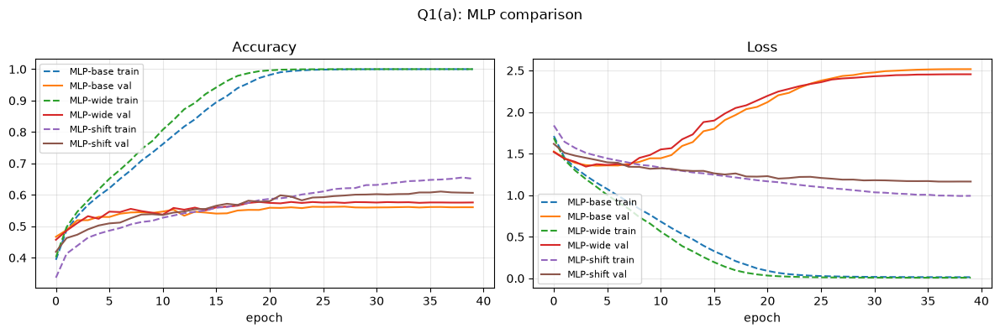

In [40]:
models, histories = {}, {}
for name, cfg in configs.items():
    set_seed()
    m = MLP(hidden=cfg["hidden"])
    models[name], histories[name] = fit(m, best_lr[name], EPOCHS, loader=cfg["loader"])

plot_curves(histories, "Q1(a): MLP comparison")

In [42]:
DROPOUTS = [0.2, 0.3, 0.5]
lr_d = best_lr["MLP-base"]            

scores = {}
for p in DROPOUTS:
    set_seed()
    model = MLP(hidden=512, dropout=p)
    _, h = fit(model, lr_d, EPOCHS, loader=train_loader,
               verbose=False, desc=f"MLP-dropout p={p}")
    scores[p] = h["best_val_acc"]
    print(f"dropout={p}  best val={scores[p]:.4f}")

best_p = max(scores, key=scores.get)
print("Chosen dropout:", best_p)

dropout=0.2  best val=0.5870


dropout=0.3  best val=0.5862


dropout=0.5  best val=0.5620
Chosen dropout: 0.2


MLP-dropout: 100%|█| 40/40 [00:47<00:00,  1.20s/it, best=0.582, train=0.863, val


Params: 1841162


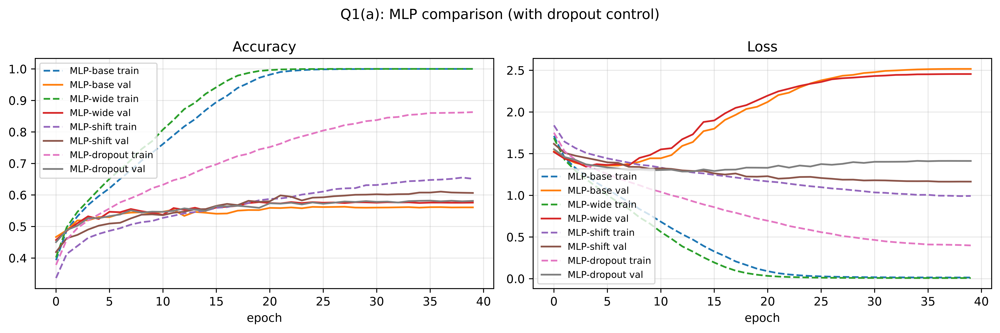

In [44]:
set_seed()
m = MLP(hidden=512, dropout=best_p)
models["MLP-dropout"], histories["MLP-dropout"] = fit(
    m, lr_d, EPOCHS, loader=train_loader, desc="MLP-dropout")

print("Params:", count_params(models["MLP-dropout"]))  
plot_curves(histories, "Q1(a): MLP comparison (with dropout control)")

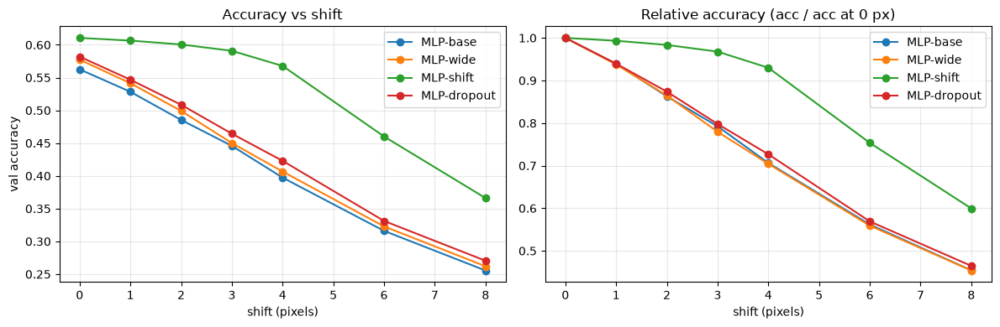

MLP-base ['0.563', '0.528', '0.485', '0.446', '0.397', '0.316', '0.256']
MLP-wide ['0.577', '0.541', '0.499', '0.450', '0.407', '0.323', '0.262']
MLP-shift ['0.611', '0.607', '0.601', '0.591', '0.568', '0.460', '0.366']
MLP-dropout ['0.582', '0.547', '0.509', '0.464', '0.423', '0.331', '0.270']


In [45]:
import torchvision.transforms.functional as TF

SHIFTS = [0, 1, 2, 3, 4, 6, 8]

@torch.no_grad()
def shift_test(model, X, y, shifts=SHIFTS):
    """Accuracy when images are moved k pixels (average of left, right, up, down)."""
    Xn = norm(X)
    accs = []
    for k in shifts:
        dir_accs = []
        for dx, dy in [(k, 0), (-k, 0), (0, k), (0, -k)]:
            Xs = TF.affine(Xn, angle=0.0, translate=[dx, dy], scale=1.0,
                           shear=[0.0], fill=0.0)
            loader = DataLoader(TensorDataset(Xs, y), batch_size=512)
            dir_accs.append(evaluate(model, loader)[1])
        accs.append(np.mean(dir_accs))
    return accs

shift_results = {name: shift_test(m, X_val, y_val) for name, m in models.items()}

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for name, accs in shift_results.items():
    ax[0].plot(SHIFTS, accs, "o-", label=name)
    ax[1].plot(SHIFTS, np.array(accs) / accs[0], "o-", label=name)
ax[0].set(title="Accuracy vs shift", xlabel="shift (pixels)", ylabel="val accuracy")
ax[1].set(title="Relative accuracy (acc / acc at 0 px)", xlabel="shift (pixels)")
for a in ax:
    a.legend()
    a.grid(alpha=0.3)
plt.tight_layout()
plt.show()

for name, accs in shift_results.items():
    print(name, [f"{a:.3f}" for a in accs])

In [46]:
test_loader_eval = DataLoader(TensorDataset(norm(X_test), y_test), batch_size=512)

print(f"{'Model':12s} {'Params':>10s} {'Test acc':>9s}")
for name, m in models.items():
    _, acc = evaluate(m, test_loader_eval)
    print(f"{name:12s} {count_params(m):>10,d} {acc:9.4f}")

# shift test on the TEST set for the final report
shift_results_test = {name: shift_test(m, X_test, y_test) for name, m in models.items()}
for name, accs in shift_results_test.items():
    print(name, [f"{a:.3f}" for a in accs])

Model            Params  Test acc
MLP-base      1,841,162    0.5603
MLP-wide      4,206,602    0.5698
MLP-shift     1,841,162    0.5939
MLP-dropout   1,841,162    0.5864
MLP-base ['0.560', '0.529', '0.487', '0.445', '0.402', '0.316', '0.256']
MLP-wide ['0.570', '0.541', '0.498', '0.453', '0.409', '0.324', '0.261']
MLP-shift ['0.594', '0.598', '0.594', '0.583', '0.567', '0.466', '0.367']
MLP-dropout ['0.586', '0.552', '0.515', '0.474', '0.432', '0.337', '0.271']


In [47]:
for name, m in models.items():
    torch.save(m.state_dict(), f"{name}.pt")

In [48]:
SEEDS = [SEED, SEED + 1, SEED + 2]

final_cfg = {
    "MLP-base":    dict(hidden=512,  dropout=0.0,    loader=train_loader, lr=best_lr["MLP-base"]),
    "MLP-wide":    dict(hidden=1024, dropout=0.0,    loader=train_loader, lr=best_lr["MLP-wide"]),
    "MLP-shift":   dict(hidden=512,  dropout=0.0,    loader=shift_loader, lr=best_lr["MLP-shift"]),
    "MLP-dropout": dict(hidden=512,  dropout=best_p, loader=train_loader, lr=best_lr["MLP-base"]),
}

runs = {name: [] for name in final_cfg}          # runs[name] = list of results, one per seed

for name, cfg in final_cfg.items():
    for s in SEEDS:
        set_seed(s)                              # starting weights + shift randomness
        cfg["loader"].generator.manual_seed(s)   # order of images in each epoch
        m = MLP(hidden=cfg["hidden"], dropout=cfg["dropout"])
        m, h = fit(m, cfg["lr"], EPOCHS, loader=cfg["loader"], desc=f"{name} seed={s}")
        torch.save(m.state_dict(), f"{name}_seed{s}.pt")
        runs[name].append({
            "seed": s,
            "model": m,
            "hist": h,
            "best_val": h["best_val_acc"],
            "shift_val": shift_test(m, X_val, y_val),
        })

MLP-base seed=26007: 100%|█| 40/40 [00:44<00:00,  1.11s/it, best=0.567, train=1.
MLP-base seed=26008: 100%|█| 40/40 [00:40<00:00,  1.02s/it, best=0.565, train=1.
MLP-base seed=26009: 100%|█| 40/40 [00:42<00:00,  1.06s/it, best=0.563, train=1.
MLP-wide seed=26007: 100%|█| 40/40 [00:49<00:00,  1.23s/it, best=0.576, train=1.
MLP-wide seed=26008: 100%|█| 40/40 [00:55<00:00,  1.39s/it, best=0.575, train=1.
MLP-wide seed=26009: 100%|█| 40/40 [00:52<00:00,  1.30s/it, best=0.573, train=1.
MLP-shift seed=26007: 100%|█| 40/40 [01:24<00:00,  2.10s/it, best=0.610, train=0
MLP-shift seed=26008: 100%|█| 40/40 [01:27<00:00,  2.18s/it, best=0.604, train=0
MLP-shift seed=26009: 100%|█| 40/40 [01:25<00:00,  2.15s/it, best=0.605, train=0
MLP-dropout seed=26007: 100%|█| 40/40 [00:46<00:00,  1.16s/it, best=0.585, train
MLP-dropout seed=26008: 100%|█| 40/40 [00:45<00:00,  1.13s/it, best=0.588, train
MLP-dropout seed=26009: 100%|█| 40/40 [00:45<00:00,  1.13s/it, best=0.588, train


In [113]:
np.mean([r["hist"]["train_acc"][-1] for r in runs[name]])

np.float64(0.8633407407407407)

In [115]:
for name in ["MLP-base", "MLP-wide", "MLP-dropout"]:
    arr = np.array([r["shift_test"] for r in runs[name]])
    print(name, "rel:", np.round((arr / arr[:, :1]).mean(0), 3))

MLP-base rel: [1.    0.943 0.868 0.793 0.712 0.565 0.459]
MLP-wide rel: [1.    0.947 0.874 0.801 0.718 0.568 0.459]
MLP-dropout rel: [1.    0.948 0.886 0.812 0.732 0.58  0.47 ]


Model            Params   Val acc (mean ± std)
MLP-base      1,841,162   0.5649 ± 0.0014
MLP-wide      4,206,602   0.5744 ± 0.0012
MLP-shift     1,841,162   0.6064 ± 0.0027
MLP-dropout   1,841,162   0.5871 ± 0.0014


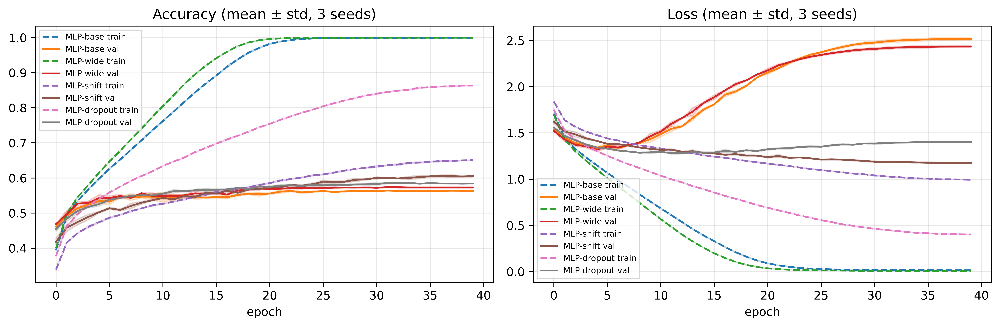

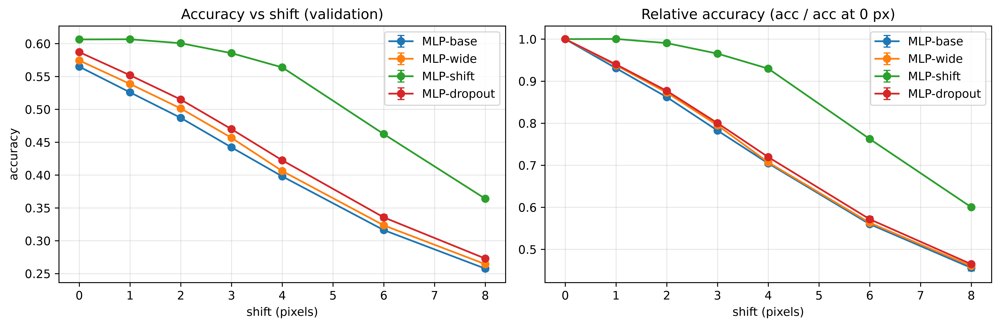

In [111]:
# ---- table ----
print(f"{'Model':12s} {'Params':>10s} {'Val acc (mean ± std)':>22s}")
for name, rs in runs.items():
    v = np.array([r["best_val"] for r in rs])
    print(f"{name:12s} {count_params(rs[0]['model']):>10,d}   {v.mean():.4f} ± {v.std():.4f}")

# ---- train/val curves: mean line + shaded std ----
fig, ax = plt.subplots(1, 2, figsize=(12, 4),dpi=800)
for name, rs in runs.items():
    for key, style, a in [("train_acc", "--", ax[0]), ("val_acc", "-", ax[0]),
                          ("train_loss", "--", ax[1]), ("val_loss", "-", ax[1])]:
        arr = np.array([r["hist"][key] for r in rs])
        mu, sd = arr.mean(0), arr.std(0)
        ep = np.arange(len(mu))
        line, = a.plot(ep, mu, style, label=f"{name} {key.split('_')[0]}")
        a.fill_between(ep, mu - sd, mu + sd, alpha=0.2, color=line.get_color())
ax[0].set(title="Accuracy (mean ± std, 3 seeds)", xlabel="epoch")
ax[1].set(title="Loss (mean ± std, 3 seeds)", xlabel="epoch")
for a in ax:
    a.legend(fontsize=7)
    a.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# ---- shift test with error bars ----
def plot_shift(runs, key, title):
    fig, ax = plt.subplots(1, 2, figsize=(12, 4),dpi=800)
    for name, rs in runs.items():
        arr = np.array([r[key] for r in rs])               # (seeds, shifts)
        rel = arr / arr[:, :1]
        ax[0].errorbar(SHIFTS, arr.mean(0), yerr=arr.std(0), marker="o", capsize=3, label=name)
        ax[1].errorbar(SHIFTS, rel.mean(0), yerr=rel.std(0), marker="o", capsize=3, label=name)
    ax[0].set(title=f"Accuracy vs shift ({title})", xlabel="shift (pixels)", ylabel="accuracy")
    ax[1].set(title="Relative accuracy (acc / acc at 0 px)", xlabel="shift (pixels)")
    for a in ax:
        a.legend()
        a.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

plot_shift(runs, "shift_val", "validation")

Model            Params   Test acc (mean ± std)
MLP-base      1,841,162   0.5617 ± 0.0005
MLP-wide      4,206,602   0.5751 ± 0.0011
MLP-shift     1,841,162   0.5973 ± 0.0023
MLP-dropout   1,841,162   0.5823 ± 0.0027


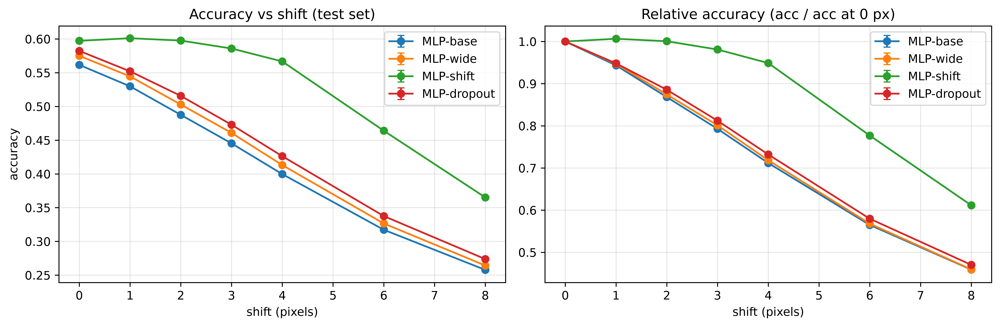

In [112]:
test_loader_eval = DataLoader(TensorDataset(norm(X_test), y_test), batch_size=512)

for name, rs in runs.items():
    for r in rs:
        r["test_acc"] = evaluate(r["model"], test_loader_eval)[1]
        r["shift_test"] = shift_test(r["model"], X_test, y_test)

print(f"{'Model':12s} {'Params':>10s} {'Test acc (mean ± std)':>23s}")
for name, rs in runs.items():
    t = np.array([r["test_acc"] for r in rs])
    print(f"{name:12s} {count_params(rs[0]['model']):>10,d}   {t.mean():.4f} ± {t.std():.4f}")

plot_shift(runs, "shift_test", "test set")

In [51]:
def make_noisy_labels(y, noise_rate, seed=SEED):
    """Change `noise_rate` of labels to a DIFFERENT random class. Returns noisy labels + mask."""
    rng = np.random.default_rng(seed)
    n = len(y)
    idx = rng.choice(n, size=int(noise_rate * n), replace=False)
    y_noisy = y.clone()
    offset = torch.tensor(rng.integers(1, 10, size=len(idx)))      # 1..9, never 0
    y_noisy[idx] = (y[idx] + offset) % 10                           # always a wrong class
    is_noisy = torch.zeros(n, dtype=torch.bool)
    is_noisy[idx] = True
    return y_noisy, is_noisy

y_noisy, is_noisy = make_noisy_labels(y_train, 0.4)
print("Fraction wrong:", (y_noisy != y_train).float().mean().item())   # should be 0.40
print("Noisy images:", is_noisy.sum().item())                          # 18000

Fraction wrong: 0.4000000059604645
Noisy images: 18000


In [52]:
Xn_train = train_loader.dataset.tensors[0]      # already-normalised train images (no extra copy)
Xn_val   = val_loader.dataset.tensors[0]

@torch.no_grad()
def predict(model, Xn, bs=1024):
    model.eval()
    return torch.cat([model(Xn[i:i+bs].to(device)).argmax(1).cpu()
                      for i in range(0, len(Xn), bs)])

def fit_memo(model, lr, epochs, y_noisy, is_noisy, desc="memorisation"):
    g = torch.Generator().manual_seed(SEED)
    loader = DataLoader(TensorDataset(Xn_train, y_noisy), batch_size=128,
                        shuffle=True, generator=g)
    model = model.to(device)
    opt = torch.optim.SGD(model.parameters(), lr=lr, momentum=0.9, weight_decay=0.0)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)

    clean = ~is_noisy
    hist = {k: [] for k in ["train_loss", "clean_acc", "mem_acc", "noisy_true_acc", "val_acc"]}
    best_val, best_state, best_ep = 0.0, None, 0

    pbar = tqdm(range(1, epochs + 1), desc=desc, ncols=120)
    for ep in pbar:
        model.train()
        tot, n = 0.0, 0
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            loss = F.cross_entropy(model(x), y)
            opt.zero_grad(); loss.backward(); opt.step()
            tot += loss.item() * y.size(0); n += y.size(0)
        sched.step()

        # ---- measurements on the training images (eval mode) ----
        p = predict(model, Xn_train)
        hist["train_loss"].append(tot / n)
        hist["clean_acc"].append((p[clean] == y_train[clean]).float().mean().item())
        if is_noisy.any():
            hist["mem_acc"].append((p[is_noisy] == y_noisy[is_noisy]).float().mean().item())
            hist["noisy_true_acc"].append((p[is_noisy] == y_train[is_noisy]).float().mean().item())
        else:
            hist["mem_acc"].append(np.nan); hist["noisy_true_acc"].append(np.nan)

        # ---- validation ----
        val_acc = (predict(model, Xn_val) == y_val).float().mean().item()
        hist["val_acc"].append(val_acc)
        if val_acc > best_val:
            best_val, best_ep = val_acc, ep
            best_state = copy.deepcopy(model.state_dict())

        pbar.set_postfix_str(f"ep {ep} | clean {hist['clean_acc'][-1]:.3f} | "
                             f"mem {hist['mem_acc'][-1]:.3f} | val {val_acc:.3f}")

    hist["best_val"], hist["best_ep"] = best_val, best_ep
    return model, best_state, hist

In [53]:
EPOCHS_MEM = 150
LR_MEM = best_lr["MLP-base"]            # reused from Q1(a)

memo = {}
for noise in [0.4, 0.0]:
    yn, mask = make_noisy_labels(y_train, noise)
    set_seed()
    big = MLP(hidden=2048)               # 3072-2048-2048-10, ~10.5M params, no dropout
    print(f"noise={noise}  params={count_params(big):,}")
    final_model, best_state, h = fit_memo(big, LR_MEM, EPOCHS_MEM, yn, mask,
                                          desc=f"noise={noise}")
    memo[noise] = dict(model=final_model, best_state=best_state, hist=h,
                       y_noisy=yn, is_noisy=mask)
    torch.save(final_model.state_dict(), f"Q1b_noise{noise}_final.pt")
    torch.save(best_state,               f"Q1b_noise{noise}_best.pt")

noise=0.4  params=10,510,346


noise=0.4: 100%|████████████████████████| 150/150 [05:35<00:00,  2.24s/it, ep 150 | clean 1.000 | mem 1.000 | val 0.389]


noise=0.0  params=10,510,346


noise=0.0: 100%|██████████████████████████| 150/150 [05:08<00:00,  2.06s/it, ep 150 | clean 1.000 | mem nan | val 0.574]


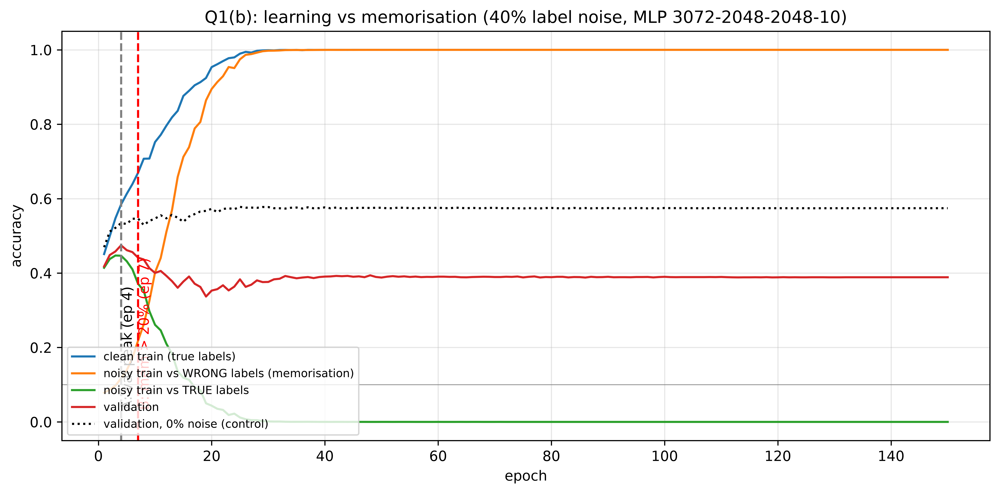

Epoch A (val peak): 4, val = 0.4746, mem at A = 0.117
Epoch B (mem > 20%): 7
Final epoch: val = 0.3888, mem = 1.000


In [56]:
h = memo[0.4]["hist"]
ep = np.arange(1, EPOCHS_MEM + 1)

A = h["best_ep"]                                                  
B = next((i + 1 for i, a in enumerate(h["mem_acc"]) if a > 0.20), None)  # memorisation starts

plt.figure(figsize=(10, 5),dpi=800)
plt.plot(ep, h["clean_acc"],      label="clean train (true labels)")
plt.plot(ep, h["mem_acc"],        label="noisy train vs WRONG labels (memorisation)")
plt.plot(ep, h["noisy_true_acc"], label="noisy train vs TRUE labels")
plt.plot(ep, h["val_acc"],        label="validation")
plt.plot(ep, memo[0.0]["hist"]["val_acc"], "k:", label="validation, 0% noise (control)")
plt.axvline(A, color="gray", ls="--")
plt.text(A, 0.02, f" A: val peak (ep {A})", rotation=90, va="bottom")
if B:
    plt.axvline(B, color="red", ls="--")
    plt.text(B, 0.02, f" B: mem > 20% (ep {B})", rotation=90, va="bottom", color="red")
plt.axhline(0.1, color="gray", lw=0.5)
plt.xlabel("epoch"); plt.ylabel("accuracy")
plt.title("Q1(b): learning vs memorisation (40% label noise, MLP 3072-2048-2048-10)")
plt.legend(fontsize=8); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

print(f"Epoch A (val peak): {A}, val = {h['best_val']:.4f}, mem at A = {h['mem_acc'][A-1]:.3f}")
print(f"Epoch B (mem > 20%): {B}")
print(f"Final epoch: val = {h['val_acc'][-1]:.4f}, mem = {h['mem_acc'][-1]:.3f}")

In [55]:
test_dl = DataLoader(TensorDataset(norm(X_test), y_test), batch_size=512)

for noise in [0.4, 0.0]:
    m = memo[noise]["model"]
    _, acc_final = evaluate(m, test_dl)
    m_best = MLP(hidden=2048).to(device)
    m_best.load_state_dict(memo[noise]["best_state"])
    _, acc_best = evaluate(m_best, test_dl)
    print(f"noise={noise}: test acc at val-peak epoch {memo[noise]['hist']['best_ep']} "
          f"= {acc_best:.4f} | at final epoch = {acc_final:.4f}")

noise=0.4: test acc at val-peak epoch 4 = 0.4720 | at final epoch = 0.3947
noise=0.0: test acc at val-peak epoch 25 = 0.5852 | at final epoch = 0.5821


In [57]:
class CNN(nn.Module):
    def __init__(self):
        super().__init__()
        def conv(i, o):
            return [nn.Conv2d(i, o, 3, padding=1), nn.ReLU()]
        self.features = nn.Sequential(
            *conv(3, 64),    *conv(64, 64),    nn.MaxPool2d(2),   # 32 -> 16
            *conv(64, 128),  *conv(128, 128),  nn.MaxPool2d(2),   # 16 -> 8
            *conv(128, 256), *conv(256, 256),  nn.MaxPool2d(2),   # 8 -> 4
            *conv(256, 256),
        )
        self.head = nn.Sequential(
            nn.AdaptiveAvgPool2d(1), nn.Flatten(),                # global average pool
            nn.Linear(256, 256), nn.ReLU(),
            nn.Linear(256, 10),
        )

    def forward(self, x):
        return self.head(self.features(x))

print("CNN params:", count_params(CNN()))          # 1,803,850
print("MLP params:", count_params(MLP(512)))       # 1,841,162

CNN params: 1803850
MLP params: 1841162


In [58]:
cnn_scores = {}
for lr in LRS:
    set_seed()
    _, h = fit(CNN(), lr, EPOCHS, loader=train_loader,
               verbose=False, desc=f"CNN lr={lr}")
    cnn_scores[lr] = h["best_val_acc"]
    print(f"CNN  lr={lr}  best val={cnn_scores[lr]:.4f}")
best_lr["CNN"] = max(cnn_scores, key=cnn_scores.get)
print("Chosen CNN LR:", best_lr["CNN"])

CNN  lr=0.1  best val=0.8264


CNN  lr=0.03  best val=0.8488


CNN  lr=0.01  best val=0.8172
Chosen CNN LR: 0.03


In [59]:
runs_q2 = {"MLP-base": runs["MLP-base"], "CNN": []}   # MLP-base reused from Q1(a)

for s in SEEDS:
    set_seed(s)
    train_loader.generator.manual_seed(s)
    m, h = fit(CNN(), best_lr["CNN"], EPOCHS, loader=train_loader, desc=f"CNN seed={s}")
    torch.save(m.state_dict(), f"CNN_seed{s}.pt")
    runs_q2["CNN"].append({"seed": s, "model": m, "hist": h,
                           "best_val": h["best_val_acc"],
                           "shift_val": shift_test(m, X_val, y_val)})

for name, rs in runs_q2.items():
    v = np.array([r["best_val"] for r in rs])
    print(f"{name:10s} {count_params(rs[0]['model']):>10,d}   val {v.mean():.4f} ± {v.std():.4f}")

CNN seed=26007: 100%|█| 40/40 [09:08<00:00, 13.71s/it, best=0.848, train=1.000, 
CNN seed=26008: 100%|█| 40/40 [08:18<00:00, 12.47s/it, best=0.850, train=1.000, 
CNN seed=26009: 100%|█| 40/40 [08:37<00:00, 12.95s/it, best=0.852, train=1.000, 


MLP-base    1,841,162   val 0.5649 ± 0.0014
CNN         1,803,850   val 0.8498 ± 0.0014


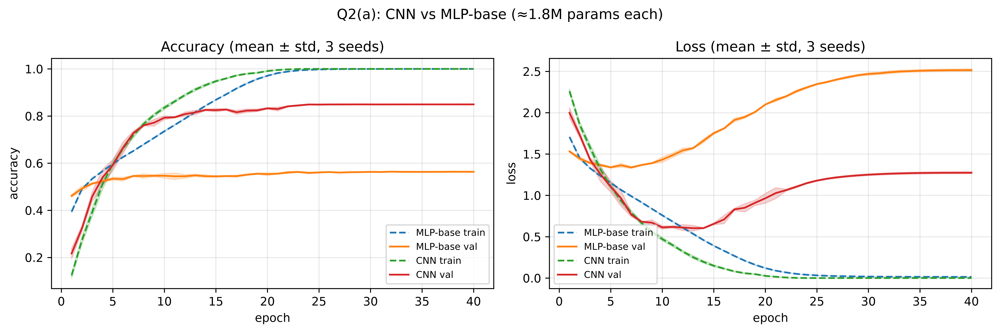

In [116]:
def plot_curves_ms(runs, title=""):
    fig, ax = plt.subplots(1, 2, figsize=(12, 4),dpi=800)
    for name, rs in runs.items():
        for key, style, a in [("train_acc", "--", ax[0]), ("val_acc", "-", ax[0]),
                              ("train_loss", "--", ax[1]), ("val_loss", "-", ax[1])]:
            arr = np.array([r["hist"][key] for r in rs])       # (seeds, epochs)
            mu, sd = arr.mean(0), arr.std(0)
            ep = np.arange(1, len(mu) + 1)
            line, = a.plot(ep, mu, style, label=f"{name} {key.split('_')[0]}")
            a.fill_between(ep, mu - sd, mu + sd, alpha=0.2, color=line.get_color())
    ax[0].set(title="Accuracy (mean ± std, 3 seeds)", xlabel="epoch", ylabel="accuracy")
    ax[1].set(title="Loss (mean ± std, 3 seeds)", xlabel="epoch", ylabel="loss")
    for a in ax:
        a.legend(fontsize=8)
        a.grid(alpha=0.3)
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

plot_curves_ms(runs_q2, "Q2(a): CNN vs MLP-base (≈1.8M params each)")

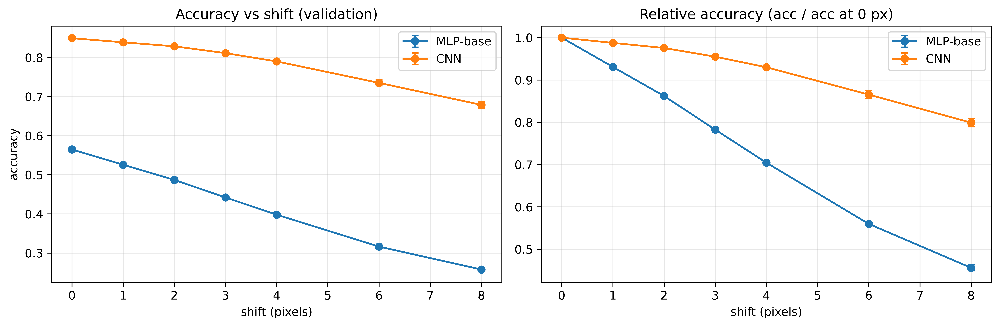

In [117]:
plot_shift(runs_q2, "shift_val", "validation")

CNN rel: [1.    0.99  0.974 0.955 0.93  0.865 0.795]


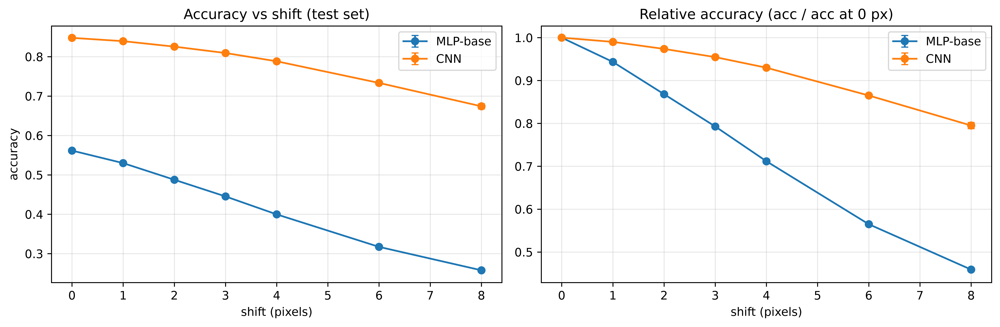

In [118]:
for r in runs_q2["CNN"]:
    if "shift_test" not in r:
        r["shift_test"] = shift_test(r["model"], X_test, y_test)
arr = np.array([r["shift_test"] for r in runs_q2["CNN"]])
print("CNN rel:", np.round((arr / arr[:, :1]).mean(0), 3))
plot_shift(runs_q2, "shift_test", "test set")      # save this as figures/q2a_shift_test.png

In [64]:
# one fixed permutation of the 1024 pixel positions, from your seed
g_perm = torch.Generator().manual_seed(SEED)
perm = torch.randperm(32 * 32, generator=g_perm)

def permute_pixels(X):
    """Same permutation for every image; the 3 colour values of a pixel move together."""
    N, C, H, W = X.shape
    return X.reshape(N, C, H * W)[:, :, perm].reshape(N, C, H, W)

Xp_train = permute_pixels(X_train)
Xp_val   = permute_pixels(X_val)
Xp_test  = permute_pixels(X_test)       # same transformation for test, as required

# pixel values are unchanged, only their positions -> same mean/std, same `norm`
train_loader_p = make_loader(Xp_train, y_train, shuffle=True)
val_loader_p   = make_loader(Xp_val,   y_val,   shuffle=False)

# sanity check
print("Same values:", torch.allclose(X_train[0].flatten().sort().values,
                                     Xp_train[0].flatten().sort().values))

Same values: True


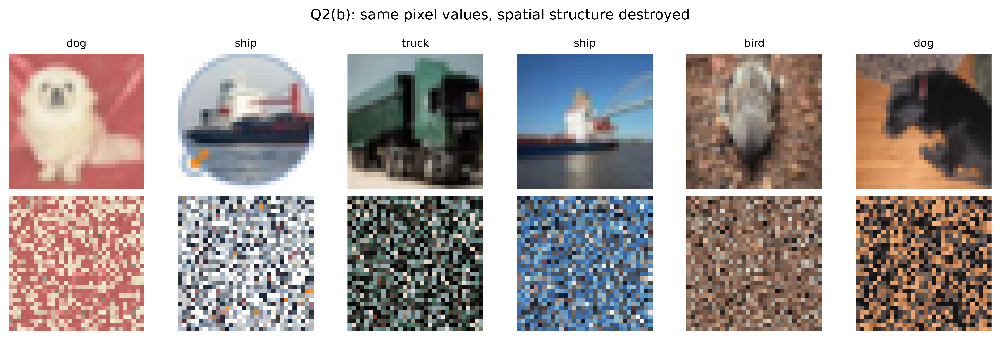

In [65]:
fig, ax = plt.subplots(2, 6, figsize=(12, 4), dpi=800)
for i in range(6):
    ax[0, i].imshow(X_val[i].permute(1, 2, 0)); ax[0, i].set_title(classes[y_val[i]], fontsize=9)
    ax[1, i].imshow(Xp_val[i].permute(1, 2, 0))
    ax[0, i].axis("off"); ax[1, i].axis("off")
ax[0, 0].set_ylabel("original"); ax[1, 0].set_ylabel("shuffled")
plt.suptitle("Q2(b): same pixel values, spatial structure destroyed")
plt.tight_layout(); plt.show()

MLP-base shuffled seed=26007: 100%|█| 40/40 [00:42<00:00,  1.07s/it, best=0.568,
MLP-base shuffled seed=26008: 100%|█| 40/40 [00:41<00:00,  1.03s/it, best=0.566,
MLP-base shuffled seed=26009: 100%|█| 40/40 [00:46<00:00,  1.16s/it, best=0.560,
CNN shuffled seed=26007: 100%|█| 40/40 [08:42<00:00, 13.06s/it, best=0.476, trai
CNN shuffled seed=26008: 100%|█| 40/40 [08:23<00:00, 12.59s/it, best=0.456, trai
CNN shuffled seed=26009: 100%|█| 40/40 [08:32<00:00, 12.82s/it, best=0.462, trai

Model               Clean val       Shuffled val   Change
MLP-base   0.5649 ± 0.0014   0.5646 ± 0.0036   -0.0 pts
CNN        0.8498 ± 0.0014   0.4648 ± 0.0080   -38.5 pts


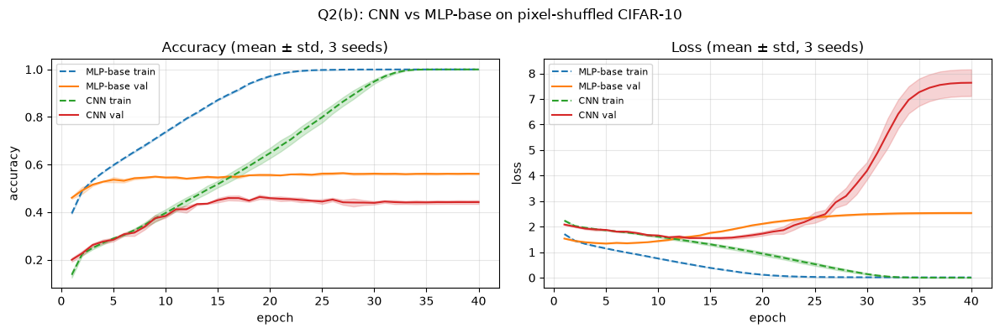

In [67]:
runs_q2b = {"MLP-base": [], "CNN": []}
builders = {"MLP-base": lambda: MLP(512), "CNN": CNN}

for name, build in builders.items():
    for s in SEEDS:
        set_seed(s)
        train_loader_p.generator.manual_seed(s)
        m, h = fit(build(), best_lr[name], EPOCHS, loader=train_loader_p,
                   val_dl=val_loader_p, desc=f"{name} shuffled seed={s}")
        torch.save(m.state_dict(), f"{name}_shuffled_seed{s}.pt")
        runs_q2b[name].append({"seed": s, "model": m, "hist": h,
                               "best_val": h["best_val_acc"]})

print(f"{'Model':10s} {'Clean val':>18s} {'Shuffled val':>18s} {'Change':>8s}")
for name in runs_q2b:
    c = np.array([r["best_val"] for r in runs_q2[name]])
    p = np.array([r["best_val"] for r in runs_q2b[name]])
    print(f"{name:10s} {c.mean():.4f} ± {c.std():.4f}   {p.mean():.4f} ± {p.std():.4f}"
          f"   {100*(p.mean()-c.mean()):+.1f} pts")

plot_curves_ms(runs_q2b, "Q2(b): CNN vs MLP-base on pixel-shuffled CIFAR-10")

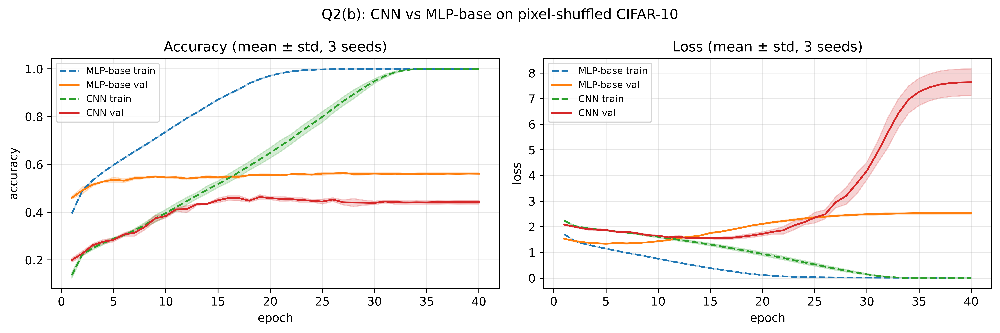

In [119]:
plot_curves_ms(runs_q2b, "Q2(b): CNN vs MLP-base on pixel-shuffled CIFAR-10")

## Question 3

### patch shuffle

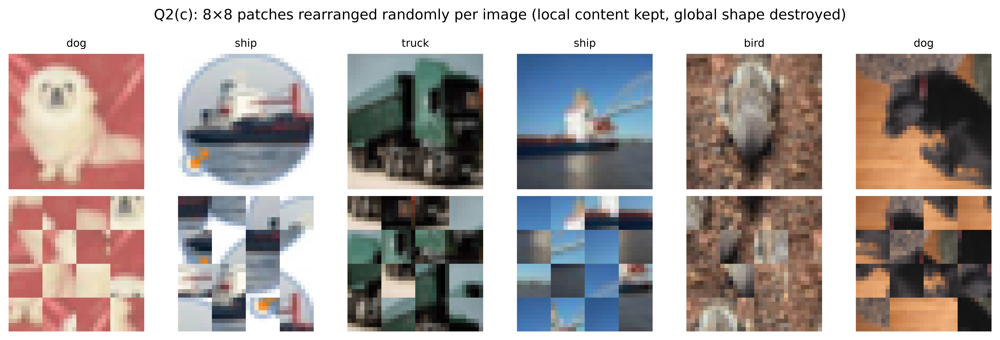

In [121]:
def patch_shuffle(X, patch=8, seed=SEED):
    """Cut each image into patch×patch blocks and rearrange them randomly (different per image)."""
    g = torch.Generator().manual_seed(seed)
    N, C, H, W = X.shape
    k = H // patch                       # 4 blocks per side -> 16 blocks
    P = k * k
    blocks = (X.reshape(N, C, k, patch, k, patch)
                .permute(0, 2, 4, 1, 3, 5)
                .reshape(N, P, C, patch, patch))
    order = torch.argsort(torch.rand(N, P, generator=g), dim=1)
    blocks = blocks[torch.arange(N)[:, None], order]
    return (blocks.reshape(N, k, k, C, patch, patch)
                  .permute(0, 3, 1, 4, 2, 5)
                  .reshape(N, C, H, W))

Xq_train = patch_shuffle(X_train, seed=SEED)
Xq_val   = patch_shuffle(X_val,   seed=SEED + 1)
Xq_test  = patch_shuffle(X_test,  seed=SEED + 2)

# pixel values unchanged -> same normalisation
train_loader_q = make_loader(Xq_train, y_train, shuffle=True)
val_loader_q   = make_loader(Xq_val,   y_val,   shuffle=False)

# figure for the report
fig, ax = plt.subplots(2, 6, figsize=(12, 4),dpi=800)
for i in range(6):
    ax[0, i].imshow(X_val[i].permute(1, 2, 0));  ax[0, i].set_title(classes[y_val[i]], fontsize=9)
    ax[1, i].imshow(Xq_val[i].permute(1, 2, 0))
    ax[0, i].axis("off"); ax[1, i].axis("off")
plt.suptitle("Q2(c): 8×8 patches rearranged randomly per image (local content kept, global shape destroyed)")
plt.tight_layout(); plt.show()

MLP-base patch seed=26007: 100%|█| 40/40 [00:46<00:00,  1.15s/it, best=0.314, tr
MLP-base patch seed=26008: 100%|█| 40/40 [00:42<00:00,  1.06s/it, best=0.321, tr
MLP-base patch seed=26009: 100%|█| 40/40 [00:39<00:00,  1.01it/s, best=0.323, tr
CNN patch seed=26007: 100%|█| 40/40 [08:16<00:00, 12.41s/it, best=0.601, train=1
CNN patch seed=26008: 100%|█| 40/40 [08:29<00:00, 12.74s/it, best=0.604, train=1
CNN patch seed=26009: 100%|█| 40/40 [08:22<00:00, 12.56s/it, best=0.597, train=1

MLP-base   patch-shuffled val 0.3195 ± 0.0040
CNN        patch-shuffled val 0.6008 ± 0.0030


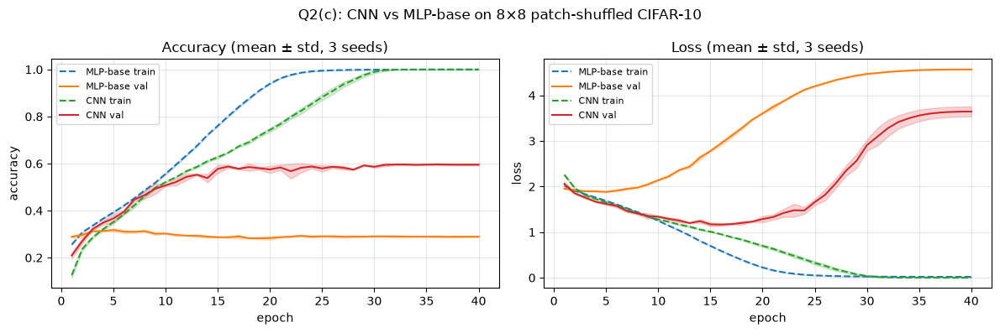

In [69]:
runs_q2c = {"MLP-base": [], "CNN": []}

for name, build in builders.items():
    for s in SEEDS:
        set_seed(s)
        train_loader_q.generator.manual_seed(s)
        m, h = fit(build(), best_lr[name], EPOCHS, loader=train_loader_q,
                   val_dl=val_loader_q, desc=f"{name} patch seed={s}")
        torch.save(m.state_dict(), f"{name}_patch_seed{s}.pt")
        runs_q2c[name].append({"seed": s, "model": m, "hist": h,
                               "best_val": h["best_val_acc"]})

for name in runs_q2c:
    v = np.array([r["best_val"] for r in runs_q2c[name]])
    print(f"{name:10s} patch-shuffled val {v.mean():.4f} ± {v.std():.4f}")

plot_curves_ms(runs_q2c, "Q2(c): CNN vs MLP-base on 8×8 patch-shuffled CIFAR-10")

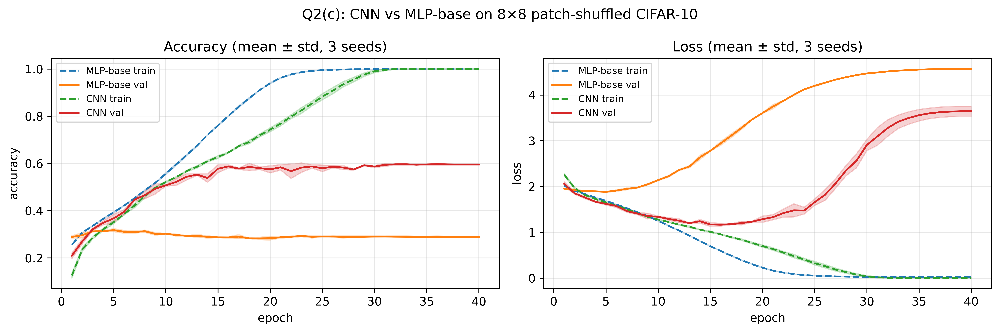

In [120]:
plot_curves_ms(runs_q2c, "Q2(c): CNN vs MLP-base on 8×8 patch-shuffled CIFAR-10")

In [70]:
@torch.no_grad()
def get_probs(model, X, bs=512):
    model.eval()
    Xn = norm(X)
    return torch.cat([F.softmax(model(Xn[i:i+bs].to(device)), 1).cpu()
                      for i in range(0, len(Xn), bs)])

def confidence_report(probs, y, n_bins=15):
    conf, pred = probs.max(1)
    correct = (pred == y)
    bins = torch.linspace(0, 1, n_bins + 1)
    ece = 0.0
    for lo, hi in zip(bins[:-1], bins[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.any():
            ece += m.float().mean() * abs(correct[m].float().mean() - conf[m].mean())
    return dict(acc=correct.float().mean().item(),
                conf_all=conf.mean().item(),
                conf_correct=conf[correct].mean().item(),
                conf_wrong=conf[~correct].mean().item(),
                ece=float(ece))

conditions = {"clean":    (runs_q2,  X_test),
              "shuffled": (runs_q2b, Xp_test),
              "patch":    (runs_q2c, Xq_test)}

results = {}
for cond, (rdict, Xt) in conditions.items():
    for name, rs in rdict.items():
        if name not in ("MLP-base", "CNN"):
            continue
        reps = []
        for r in rs:
            p = get_probs(r["model"], Xt)
            r[f"test_probs"] = p
            reps.append(confidence_report(p, y_test))
        results[(name, cond)] = {k: (np.mean([d[k] for d in reps]), np.std([d[k] for d in reps]))
                                 for k in reps[0]}

print(f"{'Model':10s} {'Condition':10s} {'Test acc':>15s} {'Conf (right)':>13s} "
      f"{'Conf (wrong)':>13s} {'ECE':>7s}")
for (name, cond), d in results.items():
    print(f"{name:10s} {cond:10s} {d['acc'][0]:.4f} ± {d['acc'][1]:.4f} "
          f"{d['conf_correct'][0]:13.3f} {d['conf_wrong'][0]:13.3f} {d['ece'][0]:7.3f}")

Model      Condition         Test acc  Conf (right)  Conf (wrong)     ECE
MLP-base   clean      0.5617 ± 0.0005         0.902         0.778   0.286
CNN        clean      0.8478 ± 0.0005         0.985         0.892   0.124
MLP-base   shuffled   0.5581 ± 0.0031         0.901         0.780   0.289
CNN        shuffled   0.4664 ± 0.0090         0.645         0.477   0.089
MLP-base   patch      0.3095 ± 0.0039         0.402         0.330   0.045
CNN        patch      0.5946 ± 0.0025         0.814         0.650   0.154





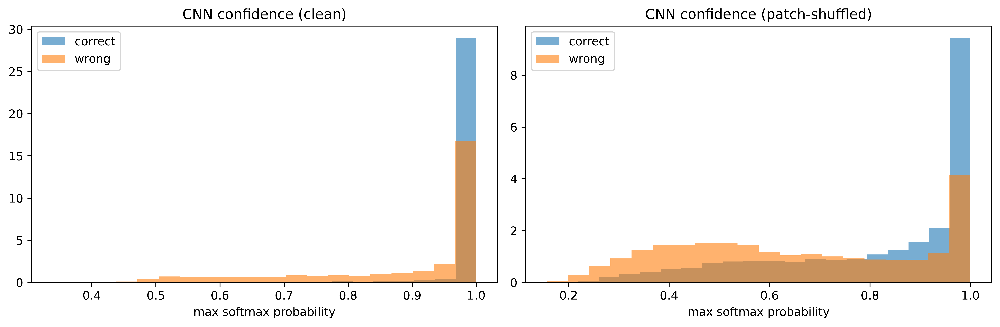

In [123]:
from sklearn.metrics import confusion_matrix

def per_class_acc(rs, y):
    preds = [r["test_probs"].argmax(1) for r in rs]
    return np.mean([[(p[y == c] == c).float().mean().item() for c in range(10)]
                    for p in preds], axis=0)

clean_pc = per_class_acc(runs_q2["CNN"],  y_test)
patch_pc = per_class_acc(runs_q2c["CNN"], y_test)

fig, ax = plt.subplots(1, 3, figsize=(17, 4.5),dpi=800)
x = np.arange(10)
ax[0].bar(x - 0.2, clean_pc, 0.4, label="clean")
ax[0].bar(x + 0.2, patch_pc, 0.4, label="patch-shuffled")
ax[0].set_xticks(x); ax[0].set_xticklabels(classes, rotation=45)
ax[0].set(title="CNN per-class test accuracy", ylabel="accuracy"); ax[0].legend()

for a, rs, t in [(ax[1], runs_q2["CNN"], "clean"), (ax[2], runs_q2c["CNN"], "patch-shuffled")]:
    cm = sum(confusion_matrix(y_test, r["test_probs"].argmax(1), labels=range(10)) for r in rs)
    cm = cm / cm.sum(1, keepdims=True)
    a.imshow(cm, cmap="Blues", vmin=0, vmax=1)
    a.set_xticks(x); a.set_xticklabels(classes, rotation=45, fontsize=8)
    a.set_yticks(x); a.set_yticklabels(classes, fontsize=8)
    a.set(title=f"CNN confusion ({t}, 3 seeds)", xlabel="predicted", ylabel="true")
plt.tight_layout(); plt.show()

# confidence histogram: correct vs wrong
fig, ax = plt.subplots(1, 2, figsize=(12, 4),dpi=800)
for a, rs, t in [(ax[0], runs_q2["CNN"], "clean"), (ax[1], runs_q2c["CNN"], "patch-shuffled")]:
    p = torch.cat([r["test_probs"] for r in rs]); yy = y_test.repeat(len(rs))
    conf, pred = p.max(1)
    a.hist(conf[pred == yy], bins=20, alpha=0.6, label="correct", density=True)
    a.hist(conf[pred != yy], bins=20, alpha=0.6, label="wrong",   density=True)
    a.set(title=f"CNN confidence ({t})", xlabel="max softmax probability"); a.legend()
plt.tight_layout(); plt.show()

In [122]:
for c in range(10):
    print(f"{classes[c]:11s} clean {clean_pc[c]:.3f}  patch {patch_pc[c]:.3f}  drop {100*(patch_pc[c]-clean_pc[c]):+.1f}")

airplane    clean 0.878  patch 0.684  drop -19.4
automobile  clean 0.928  patch 0.735  drop -19.2
bird        clean 0.767  patch 0.402  drop -36.6
cat         clean 0.721  patch 0.333  drop -38.8
deer        clean 0.831  patch 0.583  drop -24.9
dog         clean 0.782  patch 0.473  drop -30.9
frog        clean 0.885  patch 0.658  drop -22.8
horse       clean 0.873  patch 0.651  drop -22.2
ship        clean 0.913  patch 0.735  drop -17.9
truck       clean 0.900  patch 0.694  drop -20.5


## Question 3

In [72]:
class ConvAE(nn.Module):
    def __init__(self, d):
        super().__init__()
        self.d = d
        self.enc_conv = nn.Sequential(
            nn.Conv2d(3, 32, 4, stride=2, padding=1),   nn.ReLU(),   # 32 -> 16
            nn.Conv2d(32, 64, 4, stride=2, padding=1),  nn.ReLU(),   # 16 -> 8
            nn.Conv2d(64, 128, 4, stride=2, padding=1), nn.ReLU(),   # 8 -> 4
            nn.Flatten(),
        )
        self.enc_fc = nn.Linear(128 * 4 * 4, d)                       # bottleneck
        self.dec_fc = nn.Linear(d, 128 * 4 * 4)
        self.dec_conv = nn.Sequential(
            nn.ReLU(),
            nn.Unflatten(1, (128, 4, 4)),
            nn.ConvTranspose2d(128, 64, 4, stride=2, padding=1), nn.ReLU(),  # 4 -> 8
            nn.ConvTranspose2d(64, 32, 4, stride=2, padding=1),  nn.ReLU(),  # 8 -> 16
            nn.ConvTranspose2d(32, 3, 4, stride=2, padding=1),   nn.Sigmoid(),  # 16 -> 32
        )

    def encode(self, x):                 # used again in Q3(c)
        return self.enc_fc(self.enc_conv(x))

    def decode(self, z):
        return self.dec_conv(self.dec_fc(z))

    def forward(self, x):
        return self.decode(self.encode(x))

BOTTLENECKS = [32, 128, 512]
for d in BOTTLENECKS:
    print(f"AE-{d}: {count_params(ConvAE(d)):,} params")

AE-32: 464,227 params
AE-128: 857,539 params
AE-512: 2,430,787 params


In [73]:
# raw images (0-1), no labels
ae_train_loader = DataLoader(TensorDataset(X_train), batch_size=128, shuffle=True,
                             generator=torch.Generator().manual_seed(SEED))

@torch.no_grad()
def ae_mse(model, X_in, X_target, bs=512):
    """Mean squared error per pixel between model(X_in) and X_target."""
    model.eval()
    tot = 0.0
    for i in range(0, len(X_in), bs):
        out = model(X_in[i:i+bs].to(device))
        tot += F.mse_loss(out, X_target[i:i+bs].to(device), reduction="sum").item()
    return tot / X_target.numel()

def fit_ae(model, lr=1e-3, epochs=30, corrupt=None,
           val_in=None, val_target=None, desc="AE"):
    """corrupt=None -> normal AE. In Q3(b), corrupt adds noise to the INPUT only."""
    if val_in is None:     val_in = X_val
    if val_target is None: val_target = X_val
    model = model.to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    hist = {"train_mse": [], "val_mse": []}
    best, best_state, best_ep = float("inf"), None, 0

    pbar = tqdm(range(1, epochs + 1), desc=desc, ncols=120)
    for ep in pbar:
        model.train()
        tot, n = 0.0, 0
        for (x,) in ae_train_loader:
            x = x.to(device)
            inp = corrupt(x) if corrupt is not None else x
            loss = F.mse_loss(model(inp), x)          # target is always the CLEAN image
            opt.zero_grad(); loss.backward(); opt.step()
            tot += loss.item() * x.size(0); n += x.size(0)

        val = ae_mse(model, val_in, val_target)
        hist["train_mse"].append(tot / n)
        hist["val_mse"].append(val)
        if val < best:
            best, best_ep = val, ep
            best_state = copy.deepcopy(model.state_dict())
        pbar.set_postfix_str(f"ep {ep}/{epochs} | train {tot/n:.5f} | val {val:.5f} | best {best:.5f}")

    model.load_state_dict(best_state)
    hist["best_val"], hist["best_ep"] = best, best_ep
    return model, hist

In [74]:
EPOCHS_AE = 30
runs_ae = {d: [] for d in BOTTLENECKS}

for d in BOTTLENECKS:
    for s in SEEDS:
        set_seed(s)
        ae_train_loader.generator.manual_seed(s)
        m, h = fit_ae(ConvAE(d), lr=1e-3, epochs=EPOCHS_AE, desc=f"AE-{d} seed={s}")
        torch.save(m.state_dict(), f"AE{d}_seed{s}.pt")
        runs_ae[d].append({"seed": s, "model": m, "hist": h, "best_val": h["best_val"]})

AE-512 seed=26009: 100%|█████████| 30/30 [02:09<00:00,  4.31s/it, ep 30/30 | train 0.00210 | val 0.00210 | best 0.00210]


Model       d      Params     Val MSE (mean ± std)  PSNR (dB)
AE-32      32     464,227   0.01143 ± 0.00001      19.42
AE-128    128     857,539   0.00473 ± 0.00002      23.25
AE-512    512   2,430,787   0.00212 ± 0.00003      26.73

Chosen by validation MSE: AE- 512


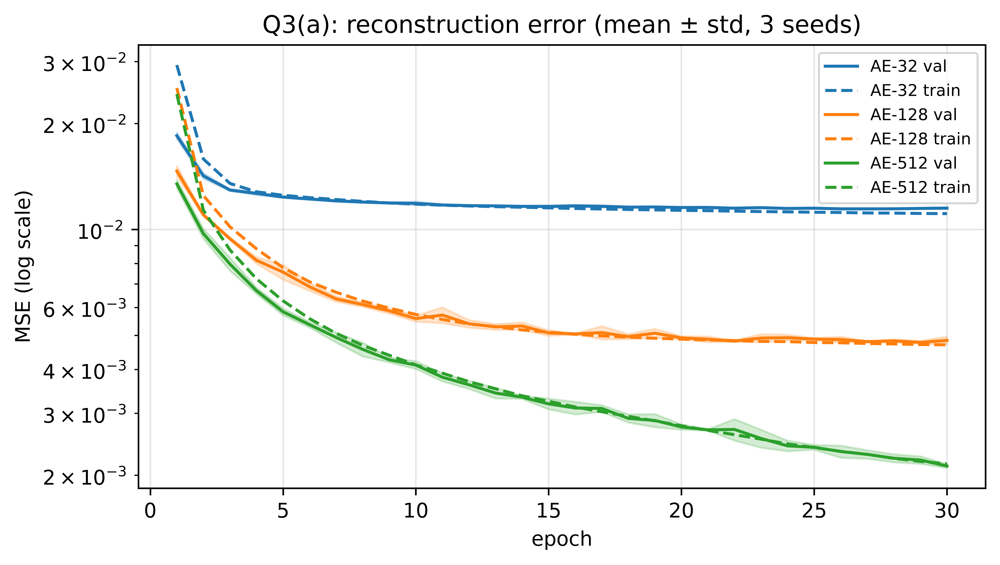

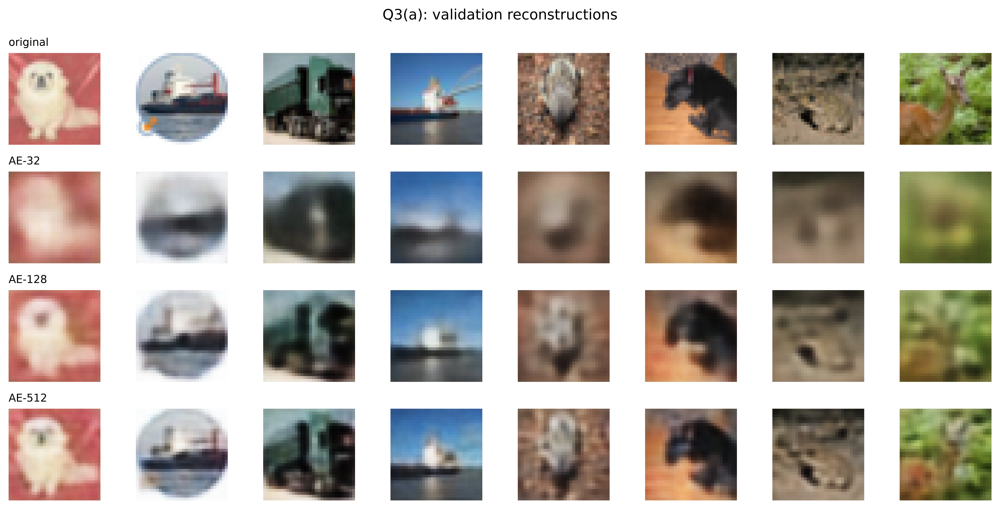

In [78]:
# ---- table ----
print(f"{'Model':8s} {'d':>4s} {'Params':>11s} {'Val MSE (mean ± std)':>24s} {'PSNR (dB)':>10s}")
val_means = {}
for d, rs in runs_ae.items():
    v = np.array([r["best_val"] for r in rs])
    val_means[d] = v.mean()
    psnr = 10 * np.log10(1 / v.mean())
    print(f"AE-{d:<5d} {d:4d} {count_params(rs[0]['model']):>11,d}   "
          f"{v.mean():.5f} ± {v.std():.5f}   {psnr:8.2f}")

chosen_d = min(val_means, key=val_means.get)
print("\nChosen by validation MSE: AE-", chosen_d)

# ---- validation curves ----
plt.figure(figsize=(7, 4),dpi=800)
for d, rs in runs_ae.items():
    arr = np.array([r["hist"]["val_mse"] for r in rs])
    mu, sd = arr.mean(0), arr.std(0); ep = np.arange(1, len(mu) + 1)
    line, = plt.plot(ep, mu, label=f"AE-{d} val")
    plt.fill_between(ep, mu - sd, mu + sd, alpha=0.2, color=line.get_color())
    arr_t = np.array([r["hist"]["train_mse"] for r in rs]).mean(0)
    plt.plot(ep, arr_t, "--", color=line.get_color(), label=f"AE-{d} train")
plt.yscale("log"); plt.xlabel("epoch"); plt.ylabel("MSE (log scale)")
plt.title("Q3(a): reconstruction error (mean ± std, 3 seeds)")
plt.legend(fontsize=8); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

# ---- example reconstructions (validation images) ----
idx = torch.arange(8)
fig, ax = plt.subplots(4, 8, figsize=(12, 6),dpi=800)
rows = [("original", X_val[idx])]
for d in BOTTLENECKS:
    m = runs_ae[d][0]["model"].eval()
    with torch.no_grad():
        rows.append((f"AE-{d}", m(X_val[idx].to(device)).cpu()))
for r, (name, imgs) in enumerate(rows):
    for c in range(8):
        ax[r, c].imshow(imgs[c].permute(1, 2, 0).clamp(0, 1)); ax[r, c].axis("off")
    ax[r, 0].set_title(name, fontsize=9, loc="left")
plt.suptitle("Q3(a): validation reconstructions"); plt.tight_layout(); plt.show()

In [76]:
t = np.array([ae_mse(r["model"], X_test, X_test) for r in runs_ae[chosen_d]])
print(f"AE-{chosen_d} test MSE: {t.mean():.5f} ± {t.std():.5f}  "
      f"(PSNR {10*np.log10(1/t.mean()):.2f} dB)")

AE-512 test MSE: 0.00214 ± 0.00003  (PSNR 26.71 dB)


In [79]:
cnn_fixed = runs_q2["CNN"][0]["model"].eval()     # fixed classifier, reused from Q2(a)

def noisy_copy(X, sigma, seed):
    """Fixed noise (same every time) for validation/test sets."""
    g = torch.Generator().manual_seed(seed)
    return (X + sigma * torch.randn(X.shape, generator=g)).clamp(0, 1)

@torch.no_grad()
def reconstruct(ae, X, bs=512):
    ae.eval()
    return torch.cat([ae(X[i:i+bs].to(device)).cpu() for i in range(0, len(X), bs)])

@torch.no_grad()
def cnn_acc(cnn, X, y, bs=512):
    """Accuracy of the fixed CNN on raw (0-1) images; normalised the same way as in Q2."""
    cnn.eval()
    Xn = norm(X)
    correct = 0
    for i in range(0, len(Xn), bs):
        correct += (cnn(Xn[i:i+bs].to(device)).argmax(1).cpu() == y[i:i+bs]).sum().item()
    return correct / len(y)

clean val acc: 0.8482
sigma=0.05  val acc: 0.7600
sigma=0.1   val acc: 0.5500
sigma=0.15  val acc: 0.3566
sigma=0.2   val acc: 0.2428
sigma=0.3   val acc: 0.1456
sigma=0.4   val acc: 0.1230
Chosen SIGMA: 0.15


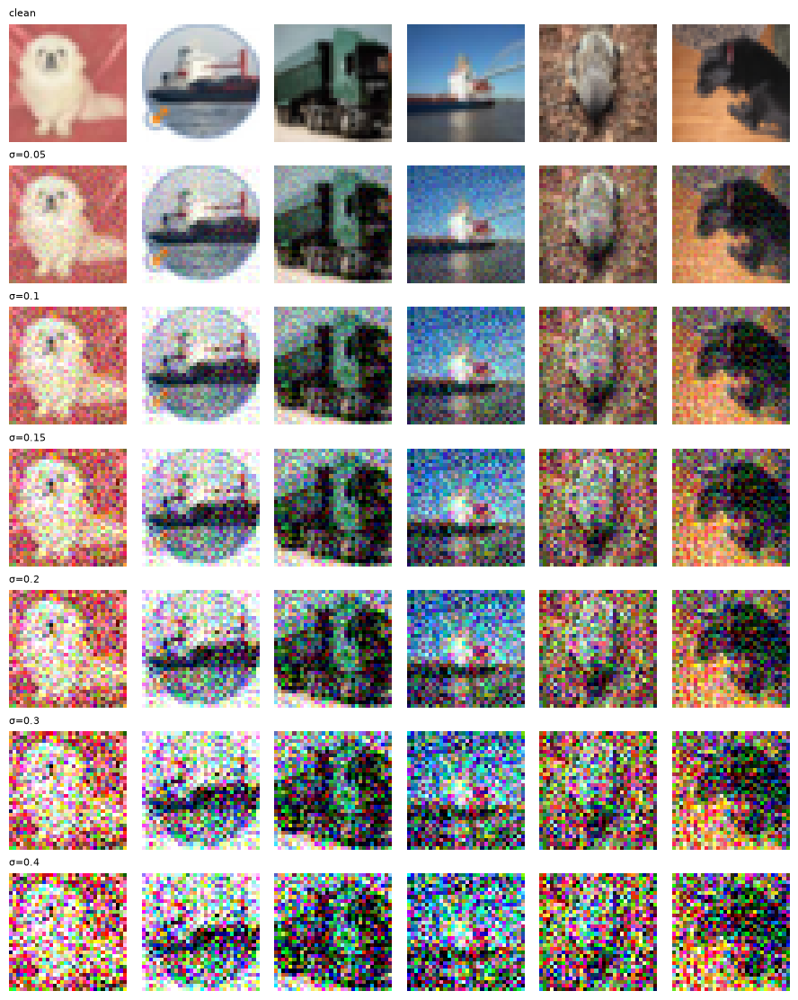

In [80]:
SIGMAS = [0.05, 0.1, 0.15, 0.2, 0.3, 0.4]

print(f"clean val acc: {cnn_acc(cnn_fixed, X_val, y_val):.4f}")
val_acc_by_sigma = {}
for s in SIGMAS:
    val_acc_by_sigma[s] = cnn_acc(cnn_fixed, noisy_copy(X_val, s, SEED + 1), y_val)
    print(f"sigma={s:<5} val acc: {val_acc_by_sigma[s]:.4f}")

SIGMA = min(s for s in SIGMAS if val_acc_by_sigma[s] < 0.5)   # rule decided beforehand
print("Chosen SIGMA:", SIGMA)

# figure: what the noise looks like
fig, ax = plt.subplots(len(SIGMAS) + 1, 6, figsize=(9, 1.6 * (len(SIGMAS) + 1)))
for c in range(6):
    ax[0, c].imshow(X_val[c].permute(1, 2, 0)); ax[0, c].axis("off")
    for r, s in enumerate(SIGMAS, 1):
        ax[r, c].imshow(noisy_copy(X_val[:6], s, SEED + 1)[c].permute(1, 2, 0))
        ax[r, c].axis("off")
ax[0, 0].set_title("clean", fontsize=8, loc="left")
for r, s in enumerate(SIGMAS, 1):
    ax[r, 0].set_title(f"σ={s}", fontsize=8, loc="left")
plt.tight_layout(); plt.show()

In [81]:
Xv_noisy = noisy_copy(X_val, SIGMA, SEED + 1)               # fixed noisy validation inputs

def add_noise_train(x):                                      # fresh noise every batch
    return (x + SIGMA * torch.randn_like(x)).clamp(0, 1)

runs_dae = []
for s in SEEDS:
    set_seed(s)
    ae_train_loader.generator.manual_seed(s)
    m, h = fit_ae(ConvAE(512), lr=1e-3, epochs=EPOCHS_AE, corrupt=add_noise_train,
                  val_in=Xv_noisy, val_target=X_val, desc=f"DAE-512 σ={SIGMA} seed={s}")
    torch.save(m.state_dict(), f"DAE512_sigma{SIGMA}_seed{s}.pt")
    runs_dae.append({"seed": s, "model": m, "hist": h, "best_val": h["best_val"]})

v = np.array([r["best_val"] for r in runs_dae])
print(f"DAE val MSE (noisy in -> clean target): {v.mean():.5f} ± {v.std():.5f}")

DAE-512 σ=0.15 seed=26009: 100%|█| 30/30 [02:25<00:00,  4.84s/it, ep 30/30 | train 0.00390 | val 0.00414 | best 0.00394]

DAE val MSE (noisy in -> clean target): 0.00397 ± 0.00002


Validation (σ = 0.15):
  noisy images              acc 0.3566
  AE-512(noisy)             acc 0.5567
  DAE(noisy)                acc 0.5211


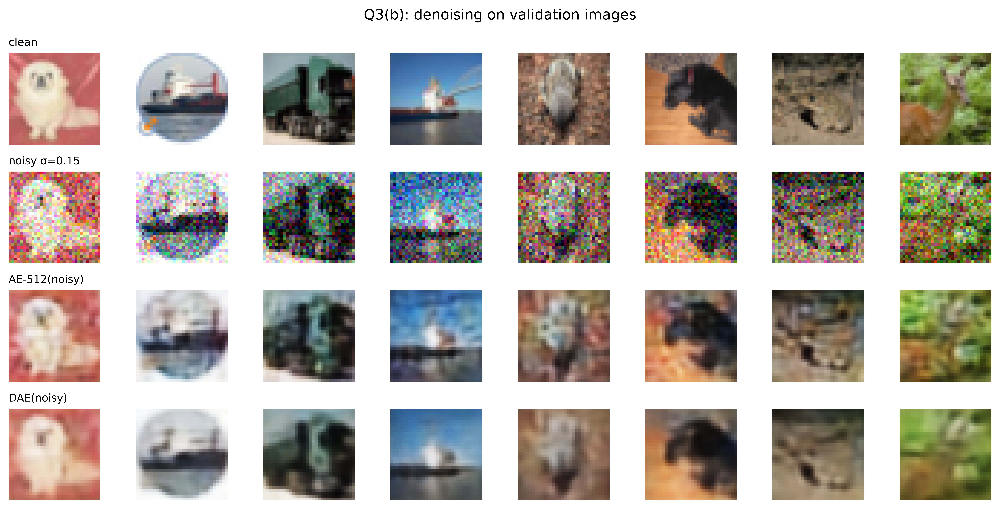

In [82]:
ae_clean = [r["model"] for r in runs_ae[512]]               # AE-512 baseline, from Q3(a)
dae      = [r["model"] for r in runs_dae]

print("Validation (σ = %.2f):" % SIGMA)
print(f"  noisy images              acc {cnn_acc(cnn_fixed, Xv_noisy, y_val):.4f}")
print(f"  AE-512(noisy)             acc {np.mean([cnn_acc(cnn_fixed, reconstruct(a, Xv_noisy), y_val) for a in ae_clean]):.4f}")
print(f"  DAE(noisy)                acc {np.mean([cnn_acc(cnn_fixed, reconstruct(d, Xv_noisy), y_val) for d in dae]):.4f}")

idx = torch.arange(8)
rows = [("clean", X_val[idx]),
        (f"noisy σ={SIGMA}", Xv_noisy[idx]),
        ("AE-512(noisy)", reconstruct(ae_clean[0], Xv_noisy[idx])),
        ("DAE(noisy)", reconstruct(dae[0], Xv_noisy[idx]))]
fig, ax = plt.subplots(4, 8, figsize=(12, 6), dpi=800)
for r, (name, imgs) in enumerate(rows):
    for c in range(8):
        ax[r, c].imshow(imgs[c].permute(1, 2, 0).clamp(0, 1)); ax[r, c].axis("off")
    ax[r, 0].set_title(name, fontsize=9, loc="left")
plt.suptitle("Q3(b): denoising on validation images"); plt.tight_layout(); plt.show()

In [83]:
Xt_noisy = noisy_copy(X_test, SIGMA, SEED + 2)              # fixed test noise

def row(name, Xs_list, target=None):
    accs = [cnn_acc(cnn_fixed, Xs, y_test) for Xs in Xs_list]
    mses = [((Xs - X_test) ** 2).mean().item() for Xs in Xs_list] if target is not None else [np.nan]
    print(f"{name:28s} acc {np.mean(accs):.4f} ± {np.std(accs):.4f}   "
          f"MSE to clean {np.nanmean(mses):.5f}")

print(f"TEST, σ = {SIGMA}, fixed CNN from Q2(a)")
row("clean images",              [X_test])
row("noisy images",              [Xt_noisy], target=True)
row("AE-512(noisy)  [baseline]", [reconstruct(a, Xt_noisy) for a in ae_clean], target=True)
row("DAE(noisy)",                [reconstruct(d, Xt_noisy) for d in dae],      target=True)
row("AE-512(clean)  [blur ctrl]",[reconstruct(a, X_test)   for a in ae_clean], target=True)
row("DAE(clean)",                [reconstruct(d, X_test)   for d in dae],      target=True)

TEST, σ = 0.15, fixed CNN from Q2(a)


/var/folders/yf/zmjlktjs7h9993ndsxqy72lr0000gn/T/ipykernel_26980/2542946556.py:7: RuntimeWarning: Mean of empty slice
  f"MSE to clean {np.nanmean(mses):.5f}")


clean images                 acc 0.8477 ± 0.0000   MSE to clean nan
noisy images                 acc 0.3625 ± 0.0000   MSE to clean 0.01992
AE-512(noisy)  [baseline]    acc 0.5570 ± 0.0042   MSE to clean 0.00492
DAE(noisy)                   acc 0.5252 ± 0.0136   MSE to clean 0.00398
AE-512(clean)  [blur ctrl]   acc 0.6658 ± 0.0077   MSE to clean 0.00214
DAE(clean)                   acc 0.5337 ± 0.0120   MSE to clean 0.00346


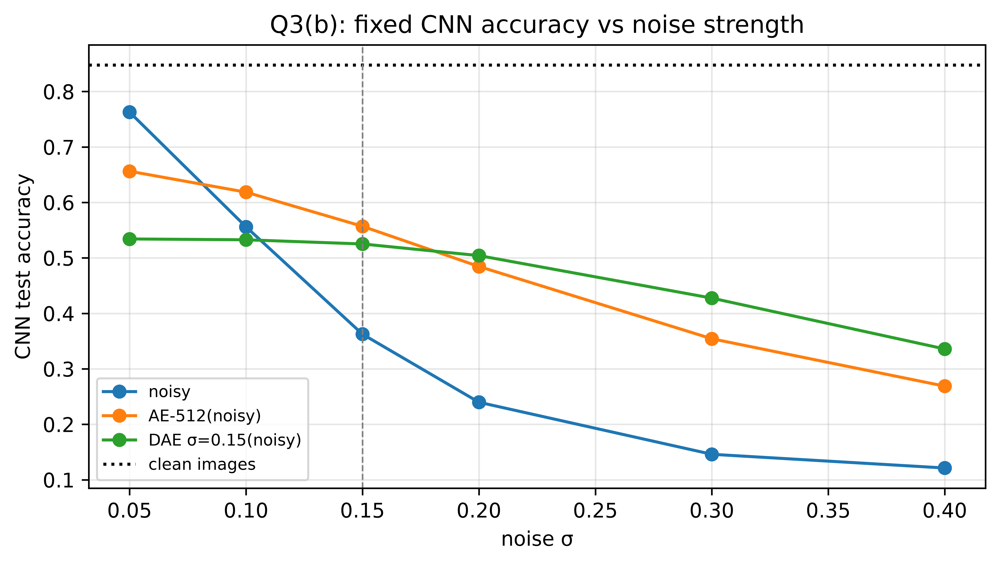

In [84]:
curve = {"noisy": [], "AE-512(noisy)": [], f"DAE σ={SIGMA}(noisy)": []}
for s in SIGMAS:
    Xs = noisy_copy(X_test, s, SEED + 2)
    curve["noisy"].append(cnn_acc(cnn_fixed, Xs, y_test))
    curve["AE-512(noisy)"].append(np.mean([cnn_acc(cnn_fixed, reconstruct(a, Xs), y_test) for a in ae_clean]))
    curve[f"DAE σ={SIGMA}(noisy)"].append(np.mean([cnn_acc(cnn_fixed, reconstruct(d, Xs), y_test) for d in dae]))

plt.figure(figsize=(7, 4),dpi=800)
for k, v in curve.items():
    plt.plot(SIGMAS, v, "o-", label=k)
plt.axhline(cnn_acc(cnn_fixed, X_test, y_test), color="k", ls=":", label="clean images")
plt.axvline(SIGMA, color="gray", ls="--", lw=0.8)
plt.xlabel("noise σ"); plt.ylabel("CNN test accuracy")
plt.title("Q3(b): fixed CNN accuracy vs noise strength")
plt.legend(fontsize=8); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

#  3 c

In [85]:
@torch.no_grad()
def encode_all(ae, X, bs=512):
    ae.eval()
    return torch.cat([ae.encode(X[i:i+bs].to(device)).cpu() for i in range(0, len(X), bs)])

def linear_probe(Ztr, Zva, Zte, wds=(0.0, 1e-4, 1e-3, 1e-2), epochs=30, seed=SEED):
    """Linear classifier on frozen features. Weight decay + epoch chosen on validation."""
    mu, sd = Ztr.mean(0, keepdim=True), Ztr.std(0, keepdim=True) + 1e-6
    Ztr, Zva, Zte = [((Z - mu) / sd) for Z in (Ztr, Zva, Zte)]
    Zva_d, Zte_d = Zva.to(device), Zte.to(device)

    best = {"val": -1}
    for wd in wds:
        set_seed(seed)
        lin = nn.Linear(Ztr.shape[1], 10).to(device)
        opt = torch.optim.Adam(lin.parameters(), lr=1e-3, weight_decay=wd)
        g = torch.Generator().manual_seed(seed)
        dl = DataLoader(TensorDataset(Ztr, y_train), batch_size=256, shuffle=True, generator=g)
        for ep in range(epochs):
            lin.train()
            for z, y in dl:
                z, y = z.to(device), y.to(device)
                loss = F.cross_entropy(lin(z), y)
                opt.zero_grad(); loss.backward(); opt.step()
            lin.eval()
            with torch.no_grad():
                va = (lin(Zva_d).argmax(1).cpu() == y_val).float().mean().item()
            if va > best["val"]:
                with torch.no_grad():
                    te = (lin(Zte_d).argmax(1).cpu() == y_test).float().mean().item()
                best = {"val": va, "test": te, "wd": wd, "ep": ep + 1}
    return best

In [86]:
probe = {}

# ---- raw pixels (reference) ----
r = linear_probe(X_train.flatten(1), X_val.flatten(1), X_test.flatten(1))
probe["Raw pixels"] = {"dims": 3072, "recon": [0.0], "val": [r["val"]], "test": [r["test"]]}
print("Raw pixels", r)

# ---- random untrained encoder (control) ----
rows = {"val": [], "test": []}
for s in SEEDS:
    set_seed(s)
    enc = ConvAE(512).to(device)
    r = linear_probe(encode_all(enc, X_train), encode_all(enc, X_val), encode_all(enc, X_test), seed=s)
    rows["val"].append(r["val"]); rows["test"].append(r["test"])
probe["Random encoder (d=512)"] = {"dims": 512, "recon": [np.nan], **rows}

# ---- trained autoencoders (Q3a) and DAE (Q3b) ----
encoders = {f"AE-{d}": [r["model"] for r in runs_ae[d]] for d in BOTTLENECKS}
encoders["DAE-512"] = [r["model"] for r in runs_dae]

for name, models_ in encoders.items():
    rows = {"val": [], "test": [], "recon": []}
    for m, s in zip(models_, SEEDS):
        r = linear_probe(encode_all(m, X_train), encode_all(m, X_val), encode_all(m, X_test), seed=s)
        rows["val"].append(r["val"]); rows["test"].append(r["test"])
        rows["recon"].append(ae_mse(m, X_test, X_test))          # clean test reconstruction
    probe[name] = {"dims": models_[0].d, **rows}
    print(name, f"probe test {np.mean(rows['test']):.4f}  recon {np.mean(rows['recon']):.5f}")

Raw pixels {'val': 0.3968000113964081, 'test': 0.397599995136261, 'wd': 0.01, 'ep': 30}
AE-32 probe test 0.3674  recon 0.01146
AE-128 probe test 0.4030  recon 0.00475
AE-512 probe test 0.4634  recon 0.00214
DAE-512 probe test 0.4838  recon 0.00346


Representation            Dims     Test recon MSE  Probe val         Probe test
Raw pixels                3072  0.00000 ± 0.00000     0.3968 0.3976 ± 0.0000
Random encoder (d=512)     512                  —     0.4563 0.4575 ± 0.0035
AE-32                       32  0.01146 ± 0.00001     0.3737 0.3674 ± 0.0051
AE-128                     128  0.00475 ± 0.00003     0.4055 0.4030 ± 0.0021
AE-512                     512  0.00214 ± 0.00003     0.4704 0.4634 ± 0.0032
DAE-512                    512  0.00346 ± 0.00004     0.4889 0.4838 ± 0.0040


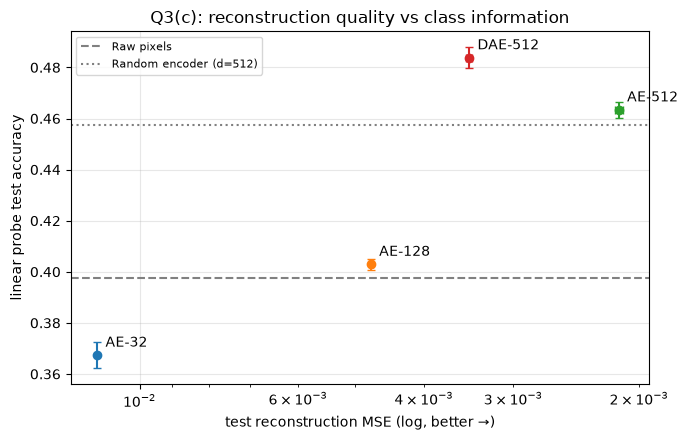

In [87]:
print(f"{'Representation':24s} {'Dims':>5s} {'Test recon MSE':>18s} {'Probe val':>10s} {'Probe test':>18s}")
for name, p in probe.items():
    rec = np.array(p["recon"]); t = np.array(p["test"])
    rec_s = "—" if np.isnan(rec).all() else f"{np.nanmean(rec):.5f} ± {np.nanstd(rec):.5f}"
    print(f"{name:24s} {p['dims']:5d} {rec_s:>18s} {np.mean(p['val']):10.4f} "
          f"{t.mean():.4f} ± {t.std():.4f}")

# ---- reconstruction vs class information ----
plt.figure(figsize=(7, 4.5))
for name in ["AE-32", "AE-128", "AE-512", "DAE-512"]:
    p = probe[name]
    plt.errorbar(np.mean(p["recon"]), np.mean(p["test"]),
                 xerr=np.std(p["recon"]), yerr=np.std(p["test"]), fmt="o", capsize=3)
    plt.annotate(name, (np.mean(p["recon"]), np.mean(p["test"])),
                 textcoords="offset points", xytext=(6, 6))
for name, ls in [("Raw pixels", "--"), ("Random encoder (d=512)", ":")]:
    plt.axhline(np.mean(probe[name]["test"]), color="gray", ls=ls, label=name)
plt.xscale("log"); plt.gca().invert_xaxis()           # better reconstruction -> right
plt.xlabel("test reconstruction MSE (log, better →)")
plt.ylabel("linear probe test accuracy")
plt.title("Q3(c): reconstruction quality vs class information")
plt.legend(fontsize=8); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

In [88]:
pca_test = []
for m, s in zip(encoders["AE-512"], SEEDS):
    Ztr, Zva, Zte = encode_all(m, X_train), encode_all(m, X_val), encode_all(m, X_test)
    mean = Ztr.mean(0, keepdim=True)
    _, _, V = torch.pca_lowrank(Ztr - mean, q=32, center=False)      # PCA fitted on TRAIN only
    proj = lambda Z: (Z - mean) @ V[:, :32]
    pca_test.append(linear_probe(proj(Ztr), proj(Zva), proj(Zte), seed=s)["test"])
print(f"AE-512 → PCA 32 dims: probe test {np.mean(pca_test):.4f} ± {np.std(pca_test):.4f}")

AE-512 → PCA 32 dims: probe test 0.3873 ± 0.0002


# Question 4

In [91]:
# restore normalisation stats (train split only) under names nothing else will overwrite
DATA_MEAN = X_train.mean(dim=(0, 2, 3), keepdim=True)
DATA_STD  = X_train.std(dim=(0, 2, 3), keepdim=True)
norm = lambda x: (x - DATA_MEAN) / DATA_STD

# sanity check: the fixed CNN should give its usual validation accuracy (~0.848)
print("CNN val acc:", cnn_acc(runs_q2["CNN"][0]["model"], X_val, y_val))

CNN val acc: 0.8482


In [92]:
cnn_feat = runs_q2["CNN"][0]["model"].eval()          # fixed CNN from Q2(a), seed 1

@torch.no_grad()
def cnn_features(model, X, bs=512):
    """256-d features: conv layers -> global average pool -> fc(256) -> ReLU (before last layer)."""
    model.eval()
    Xn = norm(X)
    out = []
    for i in range(0, len(Xn), bs):
        h = model.features(Xn[i:i+bs].to(device))
        out.append(model.head[:4](h).cpu())            # AvgPool, Flatten, Linear(256,256), ReLU
    return torch.cat(out).numpy()

F_train = cnn_features(cnn_feat, X_train)
F_val   = cnn_features(cnn_feat, X_val)
F_test  = cnn_features(cnn_feat, X_test)
print(F_train.shape, F_val.shape, F_test.shape)       # (45000, 256) (5000, 256) (10000, 256)

(45000, 256) (5000, 256) (10000, 256)


In [93]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

N_SUB = 10000
sub_idx, _ = train_test_split(np.arange(len(y_train)), train_size=N_SUB,
                              stratify=y_train.numpy(), random_state=SEED % 2**32)
np.save("Q4_subset_indices.npy", sub_idx)             # keep it for the report / reproducibility

Ftr_raw, ytr = F_train[sub_idx], y_train.numpy()[sub_idx]
yva, yte = y_val.numpy(), y_test.numpy()
print("Per-class counts:", np.bincount(ytr))           # 1000 each

scaler = StandardScaler().fit(Ftr_raw)                 # fitted on the training subset only
Ftr, Fva, Fte = scaler.transform(Ftr_raw), scaler.transform(F_val), scaler.transform(F_test)

Per-class counts: [1000 1000 1000 1000 1000 1000 1000 1000 1000 1000]


In [94]:
from sklearn.svm import SVC
import time

C_VALUES = [0.001, 0.01, 0.1, 1, 10, 100]             # 6 values, 5 orders of magnitude
KERNELS  = {"linear": dict(kernel="linear"),
            "poly":   dict(kernel="poly", degree=3, gamma="scale", coef0=1.0),
            "rbf":    dict(kernel="rbf",  gamma="scale")}

sweep, svms = [], {}
for kname, kargs in KERNELS.items():
    for C in tqdm(C_VALUES, desc=kname):
        t0 = time.time()
        svm = SVC(C=C, decision_function_shape="ovo", cache_size=2000, **kargs).fit(Ftr, ytr)
        tr = svm.score(Ftr, ytr)
        va = svm.score(Fva, yva)
        sv = svm.n_support_.sum() / len(ytr)
        sweep.append(dict(kernel=kname, C=C, train_acc=tr, val_acc=va,
                          sv_frac=sv, fit_s=time.time() - t0))
        svms[(kname, C)] = svm

print(f"{'kernel':7s} {'C':>7s} {'train acc':>10s} {'val acc':>8s} {'SV frac':>8s} {'time(s)':>8s}")
for r in sweep:
    print(f"{r['kernel']:7s} {r['C']:7g} {r['train_acc']:10.4f} {r['val_acc']:8.4f} "
          f"{r['sv_frac']:8.4f} {r['fit_s']:8.1f}")

rbf: 100%|████████████████████████████████████████| 6/6 [00:41<00:00,  6.90s/it]

kernel        C  train acc  val acc  SV frac  time(s)
linear    0.001     1.0000   0.8464   0.1993      1.6
linear     0.01     1.0000   0.8462   0.0715      0.6
linear      0.1     1.0000   0.8444   0.0443      0.4
linear        1     1.0000   0.8440   0.0441      0.3
linear       10     1.0000   0.8440   0.0441      0.4
linear      100     1.0000   0.8440   0.0441      0.4
poly      0.001     0.9821   0.8180   0.7010      8.6
poly       0.01     1.0000   0.8438   0.3525      3.5
poly        0.1     1.0000   0.8456   0.1404      1.2
poly          1     1.0000   0.8460   0.0594      0.5
poly         10     1.0000   0.8432   0.0492      0.4
poly        100     1.0000   0.8432   0.0492      0.4
rbf       0.001     0.9913   0.8330   1.0000     20.5
rbf        0.01     0.9926   0.8376   0.6955     11.9
rbf         0.1     0.9957   0.8394   0.2863      4.4
rbf           1     1.0000   0.8432   0.1176      1.8
rbf          10     1.0000   0.8430   0.0874      1.4
rbf         100     1.0000  




In [124]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2), sharey=True,dpi=800)
for ax, kname in zip(axes, KERNELS):
    rs = [r for r in sweep if r["kernel"] == kname]
    Cs = [r["C"] for r in rs]
    ax.plot(Cs, [r["val_acc"] for r in rs], "o-", label="validation acc")
    ax.plot(Cs, [r["train_acc"] for r in rs], "o--", alpha=0.6, label="training acc")
    ax2 = ax.twinx()
    ax2.plot(Cs, [r["sv_frac"] for r in rs], "s-", color="tab:red", label="SV fraction")
    ax2.set_ylim(0, 1); ax2.set_ylabel("support-vector fraction", color="tab:red")
    ax.set_xscale("log"); ax.set_xlabel("C (log scale)"); ax.set_title(f"{kname} kernel")
    ax.set_ylim(0, 1.02); ax.grid(alpha=0.3)
    h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
    ax.legend(h1 + h2, l1 + l2, fontsize=8, loc="lower right")
axes[0].set_ylabel("accuracy")
plt.suptitle("Q4(a): SVM on fixed CNN features (10k training subset)")
plt.tight_layout(); plt.show()

In [96]:
best = max(sweep, key=lambda r: (r["val_acc"], -r["C"]))   # ties -> smaller C (simpler model)
best_svm = svms[(best["kernel"], best["C"])]
print(f"Selected: kernel={best['kernel']}, C={best['C']}, val acc={best['val_acc']:.4f}")

test_pred = best_svm.predict(Fte)
test_acc = (test_pred == yte).mean()
print(f"TEST accuracy of selected SVM: {test_acc:.4f}")
print(f"(For reference: the CNN itself on test = {cnn_acc(cnn_feat, X_test, y_test):.4f})")

Selected: kernel=linear, C=0.001, val acc=0.8464
TEST accuracy of selected SVM: 0.8487
(For reference: the CNN itself on test = 0.8477)


In [97]:
from sklearn.metrics import confusion_matrix
from itertools import combinations

cm_svm = confusion_matrix(yte, test_pred, labels=range(10))
pairs_all = list(combinations(range(10), 2))          # sklearn's ovo order: (0,1),(0,2),...,(8,9)
pair_col = {p: k for k, p in enumerate(pairs_all)}

conf = sorted([(cm_svm[i, j] + cm_svm[j, i], i, j) for i, j in pairs_all], reverse=True)
print(f"{'pair':22s} {'i→j':>5s} {'j→i':>5s} {'total':>6s}  (out of 2000 test images of the pair)")
for tot, i, j in conf[:6]:
    print(f"{classes[i]+' – '+classes[j]:22s} {cm_svm[i,j]:5d} {cm_svm[j,i]:5d} {tot:6d}")

HARD_PAIRS = [(i, j) for _, i, j in conf[:3]]
print("\nSelected difficult pairs:", [(classes[i], classes[j]) for i, j in HARD_PAIRS])

pair                     i→j   j→i  total  (out of 2000 test images of the pair)
cat – dog                111   106    217
automobile – truck        42    50     92
bird – deer               52    33     85
cat – frog                38    44     82
bird – cat                30    51     81
airplane – bird           26    52     78

Selected difficult pairs: [('cat', 'dog'), ('automobile', 'truck'), ('bird', 'deer')]


In [98]:
D_tr = best_svm.decision_function(Ftr)                # (10000, 45) one score per pair
D_te = best_svm.decision_function(Fte)                # (10000, 45)
starts = np.concatenate([[0], np.cumsum(best_svm.n_support_)])

def pair_support_vectors(svm, i, j):
    """Indices (into the training subset) of the support vectors of the (i, j) classifier."""
    idx_i = np.arange(starts[i], starts[i + 1])
    idx_j = np.arange(starts[j], starts[j + 1])
    ci = svm.dual_coef_[j - 1, idx_i]                  # libsvm layout for pair (i, j), i < j
    cj = svm.dual_coef_[i, idx_j]
    sv = np.concatenate([idx_i[ci != 0], idx_j[cj != 0]])
    return svm.support_[sv]                            # positions in the 10k training subset

def show_row(imgs, titles, suptitle):
    fig, ax = plt.subplots(1, len(imgs), figsize=(1.9 * len(imgs), 2.6))
    for a, im, t in zip(ax, imgs, titles):
        a.imshow(im.permute(1, 2, 0)); a.set_title(t, fontsize=7.5); a.axis("off")
    plt.suptitle(suptitle, fontsize=10); plt.tight_layout(); plt.show()

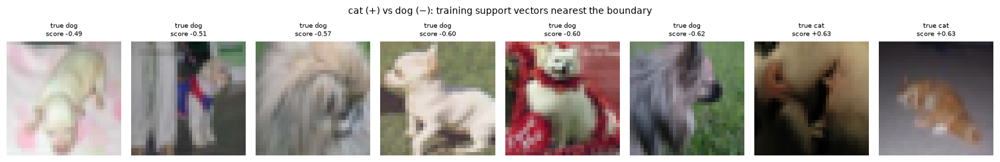

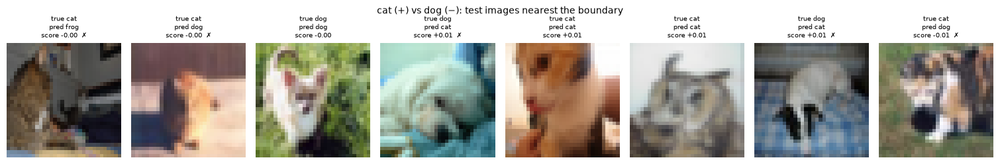

cat (+) vs dog (−): 160 SVs (8.0% of the pair's training points), 217 test errors between them, 70% of those inside the margin (|score|<1); 34.5% of the pair's test images lie inside the margin



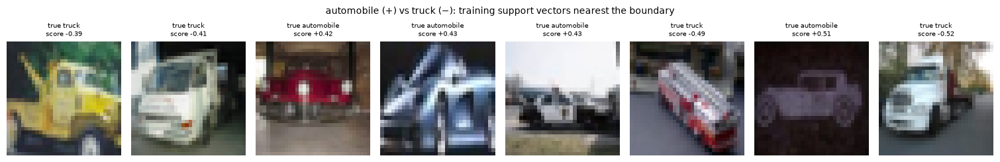

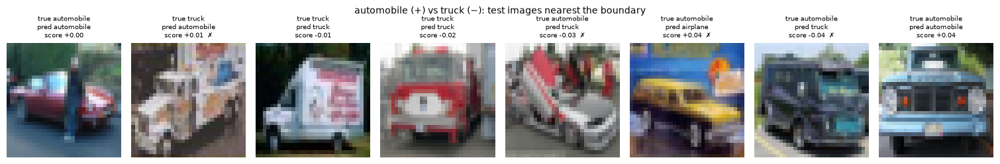

automobile (+) vs truck (−): 133 SVs (6.7% of the pair's training points), 92 test errors between them, 67% of those inside the margin (|score|<1); 15.5% of the pair's test images lie inside the margin



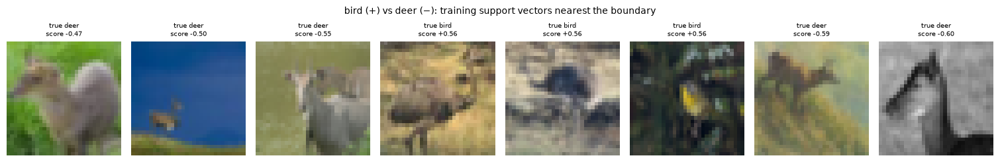

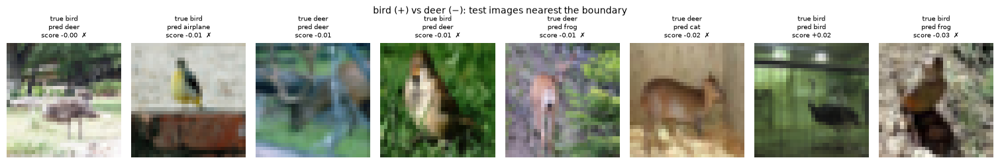

bird (+) vs deer (−): 110 SVs (5.5% of the pair's training points), 85 test errors between them, 75% of those inside the margin (|score|<1); 23.7% of the pair's test images lie inside the margin



In [99]:
X_sub = X_train[sub_idx]                               # raw images of the 10k training subset
N_SHOW = 8
pair_stats = {}

for i, j in HARD_PAIRS:
    k = pair_col[(i, j)]
    name = f"{classes[i]} (+) vs {classes[j]} (−)"

    # ---- training support vectors of this pair, closest to the boundary ----
    sv = pair_support_vectors(best_svm, i, j)
    sv_scores = D_tr[sv, k]
    order = sv[np.argsort(np.abs(sv_scores))][:N_SHOW]
    show_row([X_sub[t] for t in order],
             [f"true {classes[ytr[t]]}\nscore {D_tr[t, k]:+.2f}" for t in order],
             f"{name}: training support vectors nearest the boundary")

    # ---- test images of the two classes, closest to the boundary ----
    te_mask = np.isin(yte, [i, j])
    te_idx = np.where(te_mask)[0]
    near = te_idx[np.argsort(np.abs(D_te[te_idx, k]))][:N_SHOW]
    show_row([X_test[t] for t in near],
             [f"true {classes[yte[t]]}\npred {classes[test_pred[t]]}\nscore {D_te[t, k]:+.2f}"
              + ("  ✗" if test_pred[t] != yte[t] else "") for t in near],
             f"{name}: test images nearest the boundary")

    # ---- statistics linking errors to the boundary ----
    in_pair_pred = te_idx[np.isin(test_pred[te_idx], [i, j])]
    errs = in_pair_pred[test_pred[in_pair_pred] != yte[in_pair_pred]]
    margin_pts = np.abs(D_te[te_idx, k]) < 1
    pair_stats[(i, j)] = dict(
        n_sv=len(sv), sv_frac=len(sv) / np.isin(ytr, [i, j]).sum(),
        test_errors=len(errs),
        err_in_margin=(np.abs(D_te[errs, k]) < 1).mean() if len(errs) else np.nan,
        frac_test_in_margin=margin_pts.mean(),
        margin_width=2 / np.linalg.norm(best_svm.coef_[k]))
    s = pair_stats[(i, j)]
    print(f"{name}: {s['n_sv']} SVs ({100*s['sv_frac']:.1f}% of the pair's training points), "
          f"{s['test_errors']} test errors between them, {100*s['err_in_margin']:.0f}% of those "
          f"inside the margin (|score|<1); {100*s['frac_test_in_margin']:.1f}% of the pair's test "
          f"images lie inside the margin\n")

In [127]:
N_SHOW = 8
fig, axes = plt.subplots(6, N_SHOW, figsize=(N_SHOW * 1.6, 6 * 2.1),dpi=800)

for p, (i, j) in enumerate(HARD_PAIRS):
    k = pair_col[(i, j)]

    # top row: training support vectors nearest the boundary
    sv = pair_support_vectors(best_svm, i, j)
    sv_show = sv[np.argsort(np.abs(D_tr[sv, k]))][:N_SHOW]
    # bottom row: test images of the two classes nearest the boundary
    te_idx = np.where(np.isin(yte, [i, j]))[0]
    te_show = te_idx[np.argsort(np.abs(D_te[te_idx, k]))][:N_SHOW]

    for c in range(N_SHOW):
        a = axes[2 * p, c]
        t = sv_show[c]
        a.imshow(X_sub[t].permute(1, 2, 0)); a.axis("off")
        a.set_title(f"{classes[ytr[t]]}\n{D_tr[t, k]:+.2f}", fontsize=7)

        a = axes[2 * p + 1, c]
        t = te_show[c]
        wrong = test_pred[t] != yte[t]
        a.imshow(X_test[t].permute(1, 2, 0)); a.axis("off")
        a.set_title(f"{classes[yte[t]]}→{classes[test_pred[t]]}\n{D_te[t, k]:+.2f}"
                    + (" ✗" if wrong else ""), fontsize=7, color="red" if wrong else "black")

    axes[2 * p, 0].text(-0.15, 0.5, f"{classes[i]} vs {classes[j]}\ntrain SVs",
                        transform=axes[2 * p, 0].transAxes, ha="right", va="center", fontsize=8)
    axes[2 * p + 1, 0].text(-0.15, 0.5, "test near\nboundary",
                            transform=axes[2 * p + 1, 0].transAxes, ha="right", va="center", fontsize=8)

plt.tight_layout()
plt.show()

pair                     centroid dist within spread  ratio  margin 2/||w||
cat – dog                         9.36         10.50   0.89           5.500
automobile – truck               15.60         10.31   1.51           6.340
bird – deer                      13.00          9.45   1.38           6.740
automobile – frog                19.21          9.54   2.01           7.854  (easy reference)


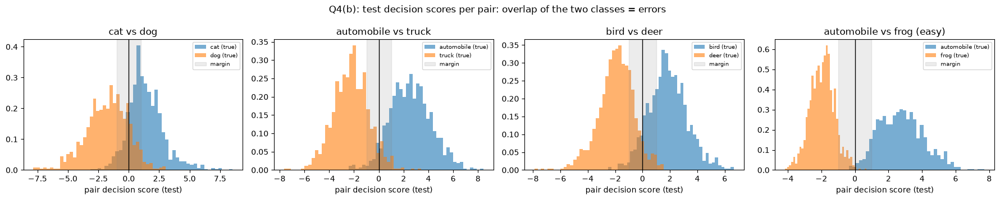

In [100]:
def pair_geometry(F, y, i, j):
    """Centroid distance vs within-class spread (standardised CNN features)."""
    A, B = F[y == i], F[y == j]
    ca, cb = A.mean(0), B.mean(0)
    between = np.linalg.norm(ca - cb)
    within = 0.5 * (np.linalg.norm(A - ca, axis=1).mean() + np.linalg.norm(B - cb, axis=1).mean())
    return between, within, between / within

# compare the hard pairs with an easy pair for reference
EASY = (1, 6)                                           # automobile vs frog
print(f"{'pair':24s} {'centroid dist':>13s} {'within spread':>13s} {'ratio':>6s} {'margin 2/||w||':>15s}")
for i, j in HARD_PAIRS + [EASY]:
    b, w, r = pair_geometry(Fte, yte, i, j)
    mw = 2 / np.linalg.norm(best_svm.coef_[pair_col[(i, j)]])
    tag = "  (easy reference)" if (i, j) == EASY else ""
    print(f"{classes[i]+' – '+classes[j]:24s} {b:13.2f} {w:13.2f} {r:6.2f} {mw:15.3f}{tag}")

# histograms of pair scores: overlap = where errors happen
fig, ax = plt.subplots(1, 4, figsize=(18, 3.6))
for a, (i, j) in zip(ax, HARD_PAIRS + [EASY]):
    k = pair_col[(i, j)]
    a.hist(D_te[yte == i, k], bins=40, alpha=0.6, label=f"{classes[i]} (true)", density=True)
    a.hist(D_te[yte == j, k], bins=40, alpha=0.6, label=f"{classes[j]} (true)", density=True)
    a.axvline(0, color="k", lw=1); a.axvspan(-1, 1, color="gray", alpha=0.15, label="margin")
    a.set(title=f"{classes[i]} vs {classes[j]}" + (" (easy)" if (i, j) == EASY else ""),
          xlabel="pair decision score (test)")
    a.legend(fontsize=7)
plt.suptitle("Q4(b): test decision scores per pair: overlap of the two classes = errors")
plt.tight_layout(); plt.show()

# 4 c

In [101]:
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score, silhouette_score

pca_c = PCA(n_components=50, random_state=SEED % 2**32).fit(Ftr)       # TRAIN subset only
Ptr, Pva, Pte = pca_c.transform(Ftr), pca_c.transform(Fva), pca_c.transform(Fte)
print(f"PCA-50 keeps {100*pca_c.explained_variance_ratio_.sum():.1f}% of the feature variance")

K_VALUES = [5, 8, 10, 12, 15, 20]
METHODS = {
    "kmeans": lambda k: KMeans(n_clusters=k, n_init=10, random_state=SEED % 2**32),
    "gmm":    lambda k: GaussianMixture(n_components=k, covariance_type="diag",
                                        n_init=3, random_state=SEED % 2**32),
}

clu_sweep, clu_models = [], {}
for mname, make in METHODS.items():
    for k in tqdm(K_VALUES, desc=mname):
        model = make(k).fit(Ptr)                       # fitted WITHOUT labels
        va_assign = model.predict(Pva)
        clu_sweep.append(dict(
            method=mname, k=k,
            val_nmi=normalized_mutual_info_score(yva, va_assign),
            val_ari=adjusted_rand_score(yva, va_assign),
            val_sil=silhouette_score(Pva, va_assign) if len(set(va_assign)) > 1 else np.nan))
        clu_models[(mname, k)] = model

print(f"{'method':7s} {'k':>3s} {'val NMI':>8s} {'val ARI':>8s} {'val silhouette':>15s}")
for r in clu_sweep:
    print(f"{r['method']:7s} {r['k']:3d} {r['val_nmi']:8.4f} {r['val_ari']:8.4f} {r['val_sil']:15.4f}")

best_c = max(clu_sweep, key=lambda r: r["val_nmi"])
final_clu = clu_models[(best_c["method"], best_c["k"])]
K_FINAL = best_c["k"]
print(f"\nSelected: {best_c['method']}, k={K_FINAL} (val NMI {best_c['val_nmi']:.4f})")

PCA-50 keeps 96.6% of the feature variance


gmm: 100%|████████████████████████████████████████| 6/6 [00:02<00:00,  2.57it/s]

method    k  val NMI  val ARI  val silhouette
kmeans    5   0.5766   0.4068          0.1852
kmeans    8   0.6648   0.5475          0.2485
kmeans   10   0.7007   0.6655          0.2483
kmeans   12   0.6623   0.5185          0.2358
kmeans   15   0.6630   0.5626          0.1993
kmeans   20   0.6390   0.4694          0.1780
gmm       5   0.0895   0.0304         -0.0082
gmm       8   0.2799   0.1314         -0.0143
gmm      10   0.4677   0.3275          0.0845
gmm      12   0.4224   0.2726          0.0458
gmm      15   0.4749   0.3282          0.0616
gmm      20   0.4820   0.3260          0.0691

Selected: kmeans, k=10 (val NMI 0.7007)


TEST ARI = 0.6689   TEST NMI = 0.6959

 cluster  airpl  autom   bird    cat   deer    dog   frog  horse   ship  truck   size  majority (purity)
       8    892     18     56     12      9      6      7     21     47     20   1088  airplane (0.82)
       6      2    875      0      1      0      0      1      0      3     32    914  automobile (0.96)
       7     27      3    755     39     34     27     27     18      6      1    937  bird (0.81)
       9     28     18     60    790     67    165     52     95     26     30   1331  cat (0.59)
       3      6      0     45     26    818     36     14     38      0      4    987  deer (0.83)
       2      1      3     31     77     13    739      9     23      0      4    900  dog (0.82)
       0      4      8     45     38     36     13    888      3      5      2   1042  frog (0.85)
       1      1      0      5     11     20     12      0    794      2      1    846  horse (0.94)
       4     25     21      3      2      3      2     

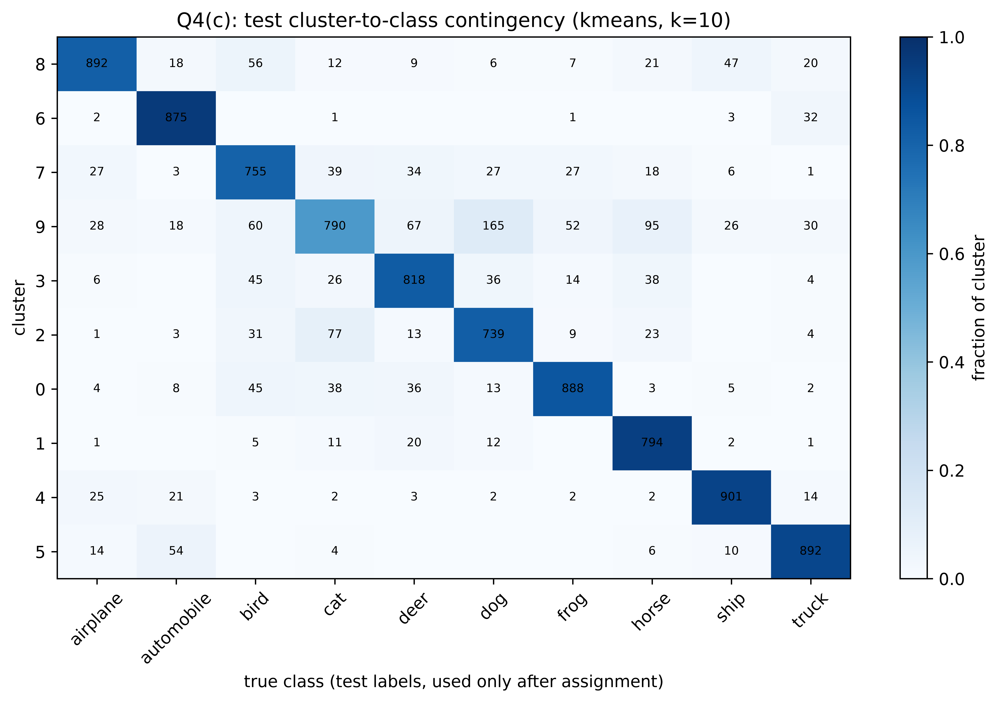

In [105]:
test_clusters = final_clu.predict(Pte)                 # assignment: NO test labels used

# ---- only now use test labels ----
test_ari = adjusted_rand_score(yte, test_clusters)
test_nmi = normalized_mutual_info_score(yte, test_clusters)
print(f"TEST ARI = {test_ari:.4f}   TEST NMI = {test_nmi:.4f}")

# contingency table: rows = clusters, columns = classes
cont = np.zeros((K_FINAL, 10), dtype=int)
for c, y in zip(test_clusters, yte):
    cont[c, y] += 1

# sort clusters by their majority class so the table reads diagonally
order = np.lexsort((-cont.max(1), cont.argmax(1)))
cont_s = cont[order]

print(f"\n{'cluster':>8s} " + " ".join(f"{c[:5]:>6s}" for c in classes) + "   size  majority (purity)")
for row, c in zip(cont_s, order):
    maj = row.argmax()
    print(f"{c:8d} " + " ".join(f"{v:6d}" for v in row) +
          f"  {row.sum():5d}  {classes[maj]} ({row.max()/row.sum():.2f})")

plt.figure(figsize=(9, 0.45 * K_FINAL + 1.5),dpi=800)
plt.imshow(cont_s / cont_s.sum(1, keepdims=True), cmap="Blues", aspect="auto", vmin=0, vmax=1)
plt.xticks(range(10), classes, rotation=45); plt.yticks(range(K_FINAL), order)
for r in range(K_FINAL):
    for c in range(10):
        if cont_s[r, c] > 0:
            plt.text(c, r, cont_s[r, c], ha="center", va="center", fontsize=7)
plt.xlabel("true class (test labels, used only after assignment)"); plt.ylabel("cluster")
plt.title(f"Q4(c): test cluster-to-class contingency ({best_c['method']}, k={K_FINAL})")
plt.colorbar(label="fraction of cluster"); plt.tight_layout(); plt.show()

class       SVM recall  largest-cluster share  clusters for 50%
airplane         0.887                  0.892                 1
automobile       0.925                  0.875                 1
bird             0.777                  0.755                 1
cat              0.714                  0.790                 1
deer             0.835                  0.818                 1
dog              0.787                  0.739                 1
frog             0.883                  0.888                 1
horse            0.866                  0.794                 1
ship             0.917                  0.901                 1
truck            0.896                  0.892                 1

pair                    SVM confusion  co-cluster prob  SVM rank  clu rank
cat – horse                     0.026            0.088        13         2
cat – truck                     0.006            0.028        27        18
bird – truck                    0.002            0.004        36      

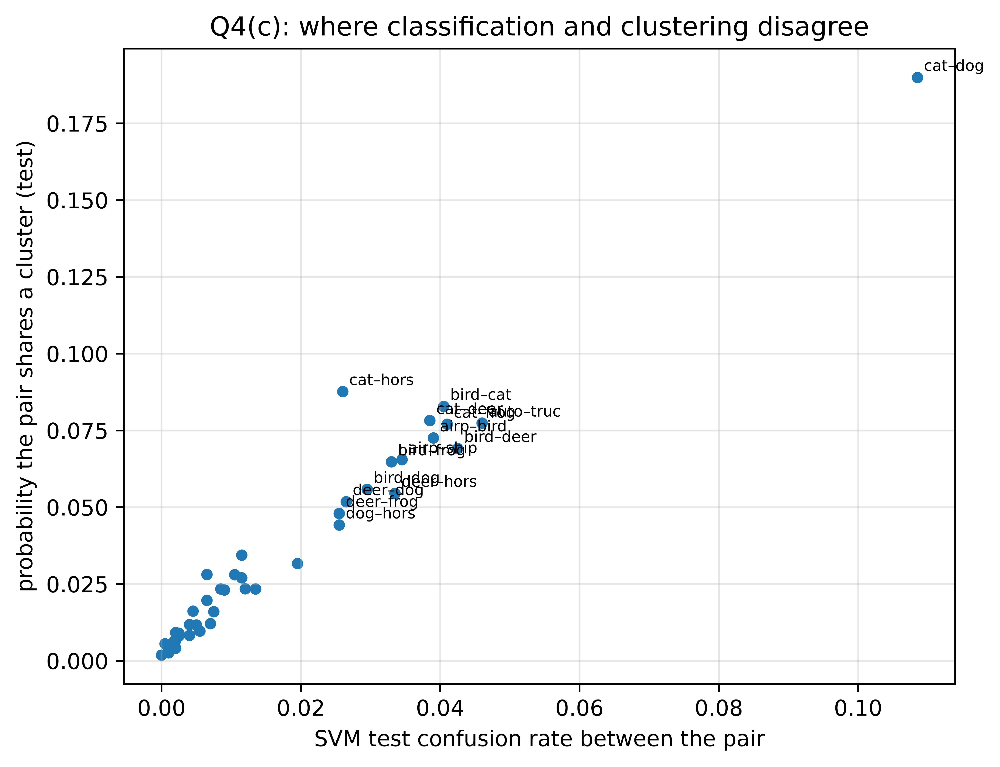

In [104]:
# ---- per class ----
svm_recall = cm_svm.diagonal() / cm_svm.sum(1)                       # SVM test recall
p_c_given_y = cont / cont.sum(0, keepdims=True)                      # P(cluster | class)
concentration = p_c_given_y.max(0)                                   # share in its biggest cluster
n_clusters_50 = [(np.cumsum(np.sort(p_c_given_y[:, y])[::-1]) < 0.5).sum() + 1 for y in range(10)]

print(f"{'class':11s} {'SVM recall':>10s} {'largest-cluster share':>22s} {'clusters for 50%':>17s}")
for y in range(10):
    print(f"{classes[y]:11s} {svm_recall[y]:10.3f} {concentration[y]:22.3f} {n_clusters_50[y]:17d}")

# ---- per pair: SVM confusion vs probability of sharing a cluster ----
rows = []
for i, j in pairs_all:
    svm_conf = (cm_svm[i, j] + cm_svm[j, i]) / (cm_svm[i].sum() + cm_svm[j].sum())
    co_clu = (p_c_given_y[:, i] * p_c_given_y[:, j]).sum()          # P(random i and random j share a cluster)
    rows.append((i, j, svm_conf, co_clu))

svm_rank = {(i, j): r for r, (i, j, *_ ) in enumerate(sorted(rows, key=lambda t: -t[2]))}
clu_rank = {(i, j): r for r, (i, j, *_ ) in enumerate(sorted(rows, key=lambda t: -t[3]))}

print(f"\n{'pair':22s} {'SVM confusion':>14s} {'co-cluster prob':>16s} {'SVM rank':>9s} {'clu rank':>9s}")
for i, j, sc, cc in sorted(rows, key=lambda t: -abs(svm_rank[(t[0], t[1])] - clu_rank[(t[0], t[1])]))[:8]:
    print(f"{classes[i]+' – '+classes[j]:22s} {sc:14.3f} {cc:16.3f} "
          f"{svm_rank[(i, j)]+1:9d} {clu_rank[(i, j)]+1:9d}")

# ---- picture: each pair as a point ----
plt.figure(figsize=(6.5, 5),dpi=800)
xs, ys = [r[2] for r in rows], [r[3] for r in rows]
plt.scatter(xs, ys, s=18)
for i, j, sc, cc in rows:
    if sc > 0.02 or cc > 0.05:
        plt.annotate(f"{classes[i][:4]}–{classes[j][:4]}", (sc, cc), fontsize=7,
                     xytext=(3, 3), textcoords="offset points")
plt.xlabel("SVM test confusion rate between the pair")
plt.ylabel("probability the pair shares a cluster (test)")
plt.title("Q4(c): where classification and clustering disagree")
plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

In [106]:
mask = (test_clusters == 9) & (yte == 7)        # horses that k-means put in the cat cluster
print(f"{mask.sum()} horses in cat cluster; SVM still predicts 'horse' for "
      f"{(test_pred[mask] == 7).mean():.1%} of them")

95 horses in cat cluster; SVM still predicts 'horse' for 53.7% of them


In [107]:
import json, pickle, os
os.makedirs("logs", exist_ok=True)

def hist_only(rdict):
    """Keep histories and numbers, drop the model objects."""
    return {name: [{k: v for k, v in r.items() if k not in ("model", "test_probs")} for r in rs]
            for name, rs in rdict.items()}

logs = {
    "q1a_runs": hist_only(runs), "q1a_best_lr": best_lr, "q1a_best_dropout": best_p,
    "q1b_memo": {str(k): {"hist": v["hist"]} for k, v in memo.items()},
    "q2a_runs": hist_only(runs_q2), "q2b_runs": hist_only(runs_q2b), "q2c_runs": hist_only(runs_q2c),
    "q2_test_results": {f"{m}|{c}": v for (m, c), v in results.items()},
    "q3a_runs": hist_only({str(d): rs for d, rs in runs_ae.items()}), "q3a_chosen_d": chosen_d,
    "q3b_sigma": SIGMA, "q3b_val_acc_by_sigma": val_acc_by_sigma, "q3b_dae": hist_only({"DAE": runs_dae}),
    "q3c_probe": probe,
    "q4a_sweep": sweep, "q4a_selected": best, "q4c_sweep": clu_sweep,
    "q4c_test": {"ari": test_ari, "nmi": test_nmi, "contingency": cont.tolist()},
}
with open("logs/all_results.pkl", "wb") as f:
    pickle.dump(logs, f)
with open("logs/all_results.json", "w") as f:
    json.dump(logs, f, indent=1, default=lambda o: o.tolist() if hasattr(o, "tolist") else float(o))
print("saved")

saved


In [108]:
os.makedirs("splits", exist_ok=True)
np.save("splits/train_idx.npy", train_idx)
np.save("splits/val_idx.npy", val_idx)
np.save("splits/q1b_noisy_idx.npy", np.where(memo[0.4]["is_noisy"].numpy())[0])
np.save("splits/q2b_pixel_perm.npy", perm.numpy())
np.save("splits/q4_subset_idx.npy", sub_idx)

In [109]:
pip freeze > requirements.txt

Note: you may need to restart the kernel to use updated packages.


In [110]:
CONFIG = dict(
    roll_number=ROLL_NUMBER, seed=SEED, seeds=[SEED, SEED+1, SEED+2],
    q1=dict(epochs=40, lrs=[0.1, 0.03, 0.01], dropouts=[0.2, 0.3, 0.5], batch=128),
    q1b=dict(noise=0.4, hidden=2048, epochs=150),
    q2=dict(epochs=40, patch=8),
    q3=dict(bottlenecks=[32, 128, 512], epochs=30, lr=1e-3,
            sigmas=[0.05, 0.1, 0.15, 0.2, 0.3, 0.4]),
    q4=dict(subset=10000, C=[0.001, 0.01, 0.1, 1, 10, 100],
            kernels=["linear", "poly", "rbf"], k_values=[5, 8, 10, 12, 15, 20], pca=50),
)
os.makedirs("configs", exist_ok=True)
json.dump(CONFIG, open("configs/config.json", "w"), indent=2)